# 생성모델-1_GAN · Diffusion

> 🎯 **없는 이미지를 만들어 내는 모델은 어떻게 학습하고, 왜 무너지나?**

위클리 페이퍼 9(GAN 생성자 · 판별자, Diffusion)와 위클리 페이퍼 11(GAN 모드 붕괴 · 원인 · 대응 · 평가)을 **3개 대단원 · 8개 섹션**으로 정리하고, 마지막 **종합 실습**에서 MNIST 작은 GAN의 정상 학습과 모드 붕괴를 숫자 분포 · 다양성 · 선명도로 비교. 1차원 → 2차원 → 이미지 순서로 데이터를 키움.

**수업 실행 코드가 없는 단원이라 코드는 모두 보강** · 개념은 위클리 9 · 11을 따르고, 코드 셀 · 실험 · 수치는 이 정리본에서 새로 작성 (섹션 제목의 <sub>개념 … · 코드 보강</sub> 표시, 코드 첫 주석의 `[보강]`)

## 이 노트북을 끝내면 답할 수 있어야 하는 질문

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">대단원</th>
<th style="text-align: left;">질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><strong>1. GAN 기본</strong></td>
<td style="text-align: left;">생성자와 판별자는 무엇을 주고받으며, 두 손실과 손실 곡선은 어떻게 읽는가?</td>
</tr>
<tr>
<td style="text-align: left;"><strong>2. 학습 균형 · 모드 붕괴</strong></td>
<td style="text-align: left;">판별자가 너무 강하거나 약하면, 생성자가 너무 앞서 나가면 어떻게 무너지고 어떻게 막는가?</td>
</tr>
<tr>
<td style="text-align: left;"><strong>3. Diffusion</strong></td>
<td style="text-align: left;">노이즈를 단계적으로 더하고 빼는 과정은 어떻게 생기고, GAN · 오토인코더와 무엇이 다른가?</td>
</tr>
<tr>
<td style="text-align: left;"><strong>4. 종합 실습</strong></td>
<td style="text-align: left;">MNIST 작은 GAN에서 정상 학습과 모드 붕괴는 숫자 분포 · 다양성 · 선명도로 어떻게 구분되는가?</td>
</tr>
</tbody>
</table>

## 읽는 법

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">표시</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code> · <code>B</code></td>
<td style="text-align: left;"><strong>A</strong> 생성 모델 코드에 바로 나오는 필수 · <strong>B</strong> 알아두면 되는 것</td>
</tr>
<tr>
<td style="text-align: left;">🎯</td>
<td style="text-align: left;">이번 섹션에서 답해야 할 질문</td>
</tr>
<tr>
<td style="text-align: left;">💡</td>
<td style="text-align: left;">쉬운 설명 · 비유</td>
</tr>
<tr>
<td style="text-align: left;">⚠️</td>
<td style="text-align: left;">자주 하는 실수</td>
</tr>
<tr>
<td style="text-align: left;">✅</td>
<td style="text-align: left;">기억할 결론 = 🎯 질문의 답</td>
</tr>
<tr>
<td style="text-align: left;"><sub>개념 위클리 · 코드 보강</sub></td>
<td style="text-align: left;">개념의 출처, 코드는 모두 보강</td>
</tr>
</tbody>
</table>

**섹션 구성** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드 → 예측 정답 · 결과 해설 → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리

**코드 주석** · 코드 위 = 이 단계에서 하는 일, 코드 옆 = 실행 흐름 · 문법 구조

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">원본</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">섹션</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">위클리 9 Q3</td>
<td style="text-align: left;">생성자 · 판별자 역할, 미니맥스 목적 함수, non-saturating 손실, 학습 한 단계 코드, 1차원 GAN 실험</td>
<td style="text-align: left;">1-1 ~ 1-3</td>
</tr>
<tr>
<td style="text-align: left;">위클리 9 Q3 보충</td>
<td style="text-align: left;">수렴 보장 없음 · 진동 · 모드 붕괴 · 기울기 포화</td>
<td style="text-align: left;">1-3 · 2-1</td>
</tr>
<tr>
<td style="text-align: left;">위클리 11</td>
<td style="text-align: left;">모드 붕괴 형태(완전 · 부분 · 호핑), 원인, 진단표, 대응 기법(균형 · 정규화 · Minibatch StdDev), FID · Precision · Recall</td>
<td style="text-align: left;">2-1 ~ 2-3 · 4장</td>
</tr>
<tr>
<td style="text-align: left;">위클리 9 Q4</td>
<td style="text-align: left;">Diffusion 전방향 · 역방향, DDPM 노이즈 일정, 2차원 8봉우리 실험, GAN · VAE · Diffusion 비교</td>
<td style="text-align: left;">3-1 · 3-2</td>
</tr>
</tbody>
</table>

### 다른 정리본과 겹치는 내용 (여기서는 참조만)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">자세한 설명</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">잠재 공간 · 인코더 · 디코더 · VAE</td>
<td style="text-align: left;">오토인코더-1 · 2</td>
</tr>
<tr>
<td style="text-align: left;">노이즈 제거 오토인코더</td>
<td style="text-align: left;">오토인코더-2</td>
</tr>
<tr>
<td style="text-align: left;">U-Net (Diffusion의 노이즈 예측 신경망)</td>
<td style="text-align: left;">세그멘테이션-1 3장</td>
</tr>
</tbody>
</table>

### 단원 연결 · 왜 이 순서로 배우는가

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">순서</th>
<th style="text-align: left;">배우는 이유</th>
<th style="text-align: left;">대단원</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">정답 없이 \"진짜 같은 것\"을 만들려면 판정자가 필요하다</td>
<td style="text-align: left;">GAN 기본 (1차원)</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">두 신경망이 경쟁하다 보니 균형이 깨지면 무너진다</td>
<td style="text-align: left;">균형 · 모드 붕괴 (2차원)</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">경쟁 없이 노이즈를 맞히는 회귀 문제로 바꾼 방법</td>
<td style="text-align: left;">Diffusion</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">1 ~ 2장을 실제 이미지에서 확인한다</td>
<td style="text-align: left;">종합 실습 (MNIST)</td>
</tr>
</tbody>
</table>

---
## 0. 준비

라이브러리 · seed · 장치를 정하고, 3-1과 4장에서 쓸 MNIST를 불러옴. 1 ~ 2장은 노트북 안에서 만든 1차원 · 2차원 데이터.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">항목</th>
<th style="text-align: left;">내용</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">재현성</td>
<td style="text-align: left;"><code>torch.manual_seed</code> · <code>cudnn.deterministic = True</code> + <code>torch.use_deterministic_algorithms(True)</code>, 데이터 · z도 seed 고정 생성기로</td>
</tr>
<tr>
<td style="text-align: left;">장치</td>
<td style="text-align: left;">GPU가 있으면 <code>cuda</code>(이때 CPU 스레드 1개), 없으면 <code>cpu</code>로 그대로 실행 (CPU에서는 2장 · 4장 학습이 수십 분)</td>
</tr>
<tr>
<td style="text-align: left;">내려받기</td>
<td style="text-align: left;">처음 실행 때만 <code>data/MNIST/</code>에 약 12MB (GitHub에는 올리지 않음)</td>
</tr>
</tbody>
</table>

In [1]:
# [보강] 라이브러리 · 재현성 · 장치 설정
import os
import random
import time
from pathlib import Path

if "KMP_DUPLICATE_LIB_OK" not in os.environ:  # Windows Anaconda 충돌 방지
    os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"  # numpy · torch OpenMP 중복
if "CUBLAS_WORKSPACE_CONFIG" not in os.environ:  # GPU 행렬 곱 결정적으로
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # torch 불러오기 전에

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
from matplotlib import font_manager
from torch import nn

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # CPU · GPU 난수 모두 고정
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True  # 합성곱 결정적
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)  # 나머지 연산도 결정적


set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":  # 계산은 GPU가 하므로 CPU 스레드는 1개로
    torch.set_num_threads(1)  # 작은 CPU 연산(증강 등)의 스레드 경쟁 방지
print("torch", torch.__version__, "| device:", device)


# 그림 한글 글꼴 (있을 때만)
fonts = {f.name for f in font_manager.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if name in fonts:
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False
bce = nn.BCEWithLogitsLoss()  # 판별자 출력 = 로짓 (sigmoid 전 점수)


def mlp(n_in, n_out, act, hidden=32):  # 은닉층 2개짜리 작은 신경망
    return nn.Sequential(nn.Linear(n_in, hidden), act,
                         nn.Linear(hidden, hidden), act,
                         nn.Linear(hidden, n_out))

torch 2.11.0+cu128 | device: cuda


In [2]:
# [보강] MNIST: 없으면 내려받음 (약 12MB, 처음 1번) · 3-1과 4장에서 사용
DATA = Path("data")  # 노트북 옆 data/ 폴더
mnist = torchvision.datasets.MNIST(DATA, train=True, download=True)
X_mnist = (mnist.data.float() / 255 * 2 - 1).view(-1, 784)  # -1 ~ 1, 펼침
Y_mnist = mnist.targets
print("MNIST:", tuple(mnist.data.shape), mnist.data.dtype,
      "→ X_mnist:", tuple(X_mnist.shape),
      "| 범위:", X_mnist.min().item(), "~", X_mnist.max().item())

MNIST: (60000, 28, 28) torch.uint8 → X_mnist: (60000, 784) | 범위: -1.0 ~ 1.0


**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>MNIST: (60000, 28, 28) torch.uint8 → X&#95;mnist: (60000, 784) &#124; 범위: -1.0 ~ 1.0</code></td>
<td style="text-align: left;">uint8 정수 → -1 ~ 1 실수로 펼침 (생성자 마지막 <code>Tanh</code> 범위와 맞춤)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 생성자 출력 범위(`Tanh` → -1 ~ 1)와 진짜 데이터 범위가 다르면 판별자가 범위만 보고 쉽게 가려냄 → 데이터를 같은 범위로 맞추기

---
## 1. GAN 기본

> **연결** · 오토인코더-1 · 2는 입력을 다시 만들었다(정답 = 입력) → 없는 데이터를 만들려면 정답이 없음. 그래서 "진짜 같은가"를 판정하는 두 번째 신경망(판별자)과 경쟁시킴

**흐름 위치** · 생성 모델 학습 흐름 — 잠재 벡터 → 생성자 → 판별자 → 두 손실 번갈아 갱신

### 1-1. `A` 생성자와 판별자의 역할 · `G(z)` · `D(x)` <sub>개념 위클리 9 Q3 · 코드 보강</sub>

> 🎯 **GAN의 생성자와 판별자는 각각 무엇을 입력받아 무엇을 내는가?**

💡 **쉽게 말하면** 생성자는 **위조지폐범**, 판별자는 **감별사**. 위조범은 진짜 지폐를 직접 본 적 없이 감별사의 반응만 보고 실력을 키우고, 감별사는 진짜와 위조를 둘 다 보며 가려내는 법을 배움.

**실행 흐름** · 봉우리 3개 1차원 진짜 데이터 → 작은 G · D 만들기 → z → G(z) → D 점수 모양 → 학습 전 진짜일 확률 → 파라미터 수

**먼저 예측** · 학습 전 판별자가 진짜 · 가짜에 내는 "진짜일 확률"은 1과 0에 가까울까? — 답은 코드 실행 결과 아래에

In [3]:
# [보강] 진짜 데이터: -3 · 0 · 3 중심 봉우리 3개 (표준편차 0.3)
MODES_1D = torch.tensor([-3.0, 0.0, 3.0])


def real_1d(n, gen):
    k = torch.randint(0, 3, (n,), generator=gen)  # 봉우리 고르기
    return (MODES_1D[k] + 0.3 * torch.randn(n, generator=gen))[:, None]


# 생성자 G: 잠재 벡터 z(4개 숫자) → 가짜 값 1개
# 판별자 D: 값 1개 → 진짜일 점수(로짓) 1개
Z1 = 4
set_seed()
G1 = mlp(Z1, 1, nn.Tanh())
D1 = mlp(1, 1, nn.LeakyReLU(0.2))
gen = torch.Generator().manual_seed(SEED)
z = torch.randn(8, Z1, generator=gen)  # 정규분포에서 뽑은 잠재 벡터
real, fake = real_1d(8, gen), G1(z)
print("z:", tuple(z.shape), "→ G(z):", tuple(fake.shape),
      "| 진짜:", tuple(real.shape))
print("D(진짜):", tuple(D1(real).shape), "| D(가짜):", tuple(D1(fake).shape))


# 학습 전: 판별자는 아직 구분 못 함 → 확률 0.5 근처
with torch.no_grad():
    print("학습 전 진짜일 확률 · 진짜:",
          round(torch.sigmoid(D1(real)).mean().item(), 4),
          "| 가짜:", round(torch.sigmoid(D1(fake)).mean().item(), 4))
print("파라미터 · G:", sum(p.numel() for p in G1.parameters()),
      "| D:", sum(p.numel() for p in D1.parameters()))

z: (8, 4) → G(z): (8, 1) | 진짜: (8, 1)
D(진짜): (8, 1) | D(가짜): (8, 1)
학습 전 진짜일 확률 · 진짜: 0.4101 | 가짜: 0.4471
파라미터 · G: 1249 | D: 1153


**예측 정답** · 아님 — 둘 다 0.4 ~ 0.45 근처, 아직 아무것도 구분 못 함

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>z: (8, 4) → G(z): (8, 1) &#124; 진짜: (8, 1)</code></td>
<td style="text-align: left;">생성자 출력은 진짜 데이터와 같은 모양이어야 판별자에 넣을 수 있음</td>
</tr>
<tr>
<td style="text-align: left;"><code>D(진짜): (8, 1) &#124; D(가짜): (8, 1)</code></td>
<td style="text-align: left;">판별자는 샘플마다 점수(로짓) 1개 = 이진 분류기</td>
</tr>
<tr>
<td style="text-align: left;"><code>학습 전 진짜일 확률 · 진짜: 0.4101 &#124; 가짜: 0.4471</code></td>
<td style="text-align: left;">무작위 가중치 → 진짜 · 가짜를 구분하지 못함</td>
</tr>
<tr>
<td style="text-align: left;"><code>파라미터 · G: 1249 &#124; D: 1153</code></td>
<td style="text-align: left;">G 4 × 32 + 32 + 32 × 32 + 32 + 32 + 1 = 1249, D 32 + 32 + 32 × 32 + 32 + 32 + 1 = 1153</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">생성자 G</td>
<td style="text-align: left;">z → 가짜 데이터, 진짜를 <strong>직접 보지 않고</strong> D를 거친 기울기로만 배움</td>
<td style="text-align: left;">학습 후 생성에 쓰는 쪽</td>
</tr>
<tr>
<td style="text-align: left;">판별자 D</td>
<td style="text-align: left;">데이터 → 진짜일 점수(로짓), 진짜 · 가짜를 모두 봄 (이진 분류기)</td>
<td style="text-align: left;">학습 중 G의 선생님, 학습 후 보통 버림</td>
</tr>
<tr>
<td style="text-align: left;">잠재 벡터 z</td>
<td style="text-align: left;">정규분포에서 뽑은 숫자 묶음, 다른 z → 다른 출력이어야 정상</td>
<td style="text-align: left;">생성 다양성의 출발점 (오토인코더-1 · 2의 잠재 공간 참조)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 판별자 마지막에 `sigmoid`를 넣고 `BCEWithLogitsLoss`까지 쓰면 sigmoid가 두 번 → 판별자는 로짓을 내고 손실이 sigmoid를 맡게 함

> ✅ **한 줄 정리** · 생성자는 잠재 벡터 z를 받아 데이터와 같은 모양의 가짜를 만들고, 판별자는 데이터를 받아 진짜일 점수 하나를 내는 이진 분류기다.

**딥러닝 코드에서는** · 학습이 끝나면 생성에는 생성자만 씀 — `G(torch.randn(n, z_dim))`, 판별자는 버림 (잠재 공간의 의미는 오토인코더-1 · 2 참조)

### 1-2. `A` 학습 한 단계와 두 손실 · `detach()` · `-log D(G(z))` <sub>개념 위클리 9 Q3 · 코드 보강</sub>

> 🎯 **판별자와 생성자는 한 단계에서 어떤 순서 · 손실로 갱신되며, 생성자 손실은 왜 원래 식 대신 -log D(G(z))를 쓰는가?**

💡 **쉽게 말하면** 감별사 시험(판별자 갱신) → 위조범 연습(생성자 갱신)을 번갈아 함. 감별사를 가르칠 때 위조범은 **잠시 멈춰 두고(detach)**, 위조범은 감별사가 **"진짜"라고 하도록** 배움.

**실행 흐름** · 옵티마이저 2개 → 판별자 손실(진짜 1 · 가짜 0, detach) → 생성자 손실(가짜를 1로) → 균형점 기준값 → 원래 식 vs non-saturating 기울기 크기

**먼저 예측** · 가짜가 쉽게 들키는 학습 초반(D(G(z)) = 0.01)에 원래 식의 기울기는 클까? — 답은 코드 실행 결과 아래에

In [4]:
# [보강] 학습 한 단계: ① 판별자 갱신 → ② 생성자 갱신
opt_g = torch.optim.Adam(G1.parameters(), lr=2e-3, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(D1.parameters(), lr=2e-3, betas=(0.5, 0.999))
ones, zeros = torch.ones(64, 1), torch.zeros(64, 1)
real = real_1d(64, gen)
fake = G1(torch.randn(64, Z1, generator=gen))


# ① 판별자: 진짜 → 1, 가짜 → 0 (가짜는 detach로 G와 끊음)
d_loss = bce(D1(real), ones) + bce(D1(fake.detach()), zeros)
opt_d.zero_grad()
d_loss.backward()
print("D 갱신 때 G 기울기 없음:", G1[0].weight.grad is None)  # detach 효과
opt_d.step()


# ② 생성자: D가 가짜를 1(진짜)이라고 하도록 → D를 거친 기울기로만 배움
g_loss = bce(D1(fake), ones)  # = 평균 -log D(G(z))
opt_g.zero_grad()
g_loss.backward()
opt_g.step()
print(f"d_loss {d_loss.item():.4f} | g_loss {g_loss.item():.4f}")
print(f"균형점 기준값 · d_loss 2·ln2 = {2 * np.log(2):.4f}"
      f" | g_loss ln2 = {np.log(2):.4f}")


# 생성자 손실 두 가지: 가짜가 쉽게 들킬 때(p 작음) 기울기 크기
for p in [0.01, 0.1, 0.5, 0.9]:  # p = D(G(z)) 진짜일 확률
    s = torch.logit(torch.tensor(p)).requires_grad_()
    torch.log(1 - torch.sigmoid(s)).backward()  # 원래 식 (줄이기)
    g_orig, s.grad = s.grad.abs().item(), None
    (-torch.log(torch.sigmoid(s))).backward()  # non-saturating
    print(f"D(G(z))={p:<4} | 원래 식 기울기 {g_orig:.2f}"
          f" | non-saturating 기울기 {s.grad.abs().item():.2f}")

D 갱신 때 G 기울기 없음: True
d_loss 1.4708 | g_loss 0.7866
균형점 기준값 · d_loss 2·ln2 = 1.3863 | g_loss ln2 = 0.6931
D(G(z))=0.01 | 원래 식 기울기 0.01 | non-saturating 기울기 0.99
D(G(z))=0.1  | 원래 식 기울기 0.10 | non-saturating 기울기 0.90
D(G(z))=0.5  | 원래 식 기울기 0.50 | non-saturating 기울기 0.50
D(G(z))=0.9  | 원래 식 기울기 0.90 | non-saturating 기울기 0.10


**예측 정답** · 아님 — 0.01로 거의 0, non-saturating은 0.99로 강한 신호

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>D 갱신 때 G 기울기 없음: True</code></td>
<td style="text-align: left;"><code>fake.detach()</code> → 판별자 손실이 생성자까지 거슬러 가지 않음</td>
</tr>
<tr>
<td style="text-align: left;"><code>d&#95;loss 1.4708 &#124; g&#95;loss 0.7866</code></td>
<td style="text-align: left;">첫 단계, 아직 균형점 근처의 무작위 상태</td>
</tr>
<tr>
<td style="text-align: left;"><code>균형점 기준값 · d&#95;loss 2·ln2 = 1.3863 &#124; g&#95;loss ln2 = 0.6931</code></td>
<td style="text-align: left;">D가 어디서나 0.5를 낼 때의 손실 (이론상 끝 상태)</td>
</tr>
<tr>
<td style="text-align: left;"><code>D(G(z))=0.01 &#124; 원래 식 기울기 0.01 &#124; non-saturating 기울기 0.99</code></td>
<td style="text-align: left;">원래 식은 들킬수록 기울기가 사라짐 (포화)</td>
</tr>
<tr>
<td style="text-align: left;"><code>D(G(z))=0.9  &#124; 원래 식 기울기 0.90 &#124; non-saturating 기울기 0.10</code></td>
<td style="text-align: left;">속이는 데 성공하면 반대로 작아짐</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">판별자 손실</td>
<td style="text-align: left;">bce(D(진짜), 1) + bce(D(가짜.detach()), 0), 균형점 2·ln2 ≈ 1.386</td>
<td style="text-align: left;">D 갱신, 가짜는 detach로 G와 끊음</td>
</tr>
<tr>
<td style="text-align: left;">생성자 손실 (non-saturating)</td>
<td style="text-align: left;">bce(D(가짜), 1) = -log D(G(z)), 균형점 ln2 ≈ 0.693</td>
<td style="text-align: left;">실제로 쓰는 생성자 손실 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">생성자 손실 (원래 식)</td>
<td style="text-align: left;">log(1 - D(G(z)))를 줄임, 가짜가 쉽게 들키는 초반에 기울기 ≈ 0</td>
<td style="text-align: left;">이론 설명용, 실제로는 안 씀</td>
</tr>
<tr>
<td style="text-align: left;">손실 값 자체</td>
<td style="text-align: left;">두 손실은 서로 상대적 → 낮다고 품질이 좋은 것이 아님</td>
<td style="text-align: left;">품질은 생성 샘플 · FID 등 따로 확인</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 생성자를 갱신할 때 판별자 옵티마이저까지 `step()`하면 판별자가 "속는 쪽"으로 학습됨 → 생성자 단계에서는 `opt_g.step()`만

> ✅ **한 줄 정리** · 판별자는 진짜 1 · 가짜 0(가짜는 detach)으로, 생성자는 가짜를 1로 맞히게 번갈아 갱신하며, 생성자 손실은 초반에도 기울기가 살아 있는 -log D(G(z))를 쓴다.

**딥러닝 코드에서는** · `d_loss = bce(D(real), 1) + bce(D(fake.detach()), 0)` → `g_loss = bce(D(fake), 1)` — DCGAN · StyleGAN 학습 루프의 뼈대

### 1-3. `A` 1차원 GAN 학습과 손실 곡선 읽기 · `d_loss` · `g_loss` · `D(real) · D(fake)` <sub>개념 위클리 9 Q3 실험 5 · 코드 보강</sub>

> 🎯 **GAN의 손실 곡선과 판별자 출력은 학습 상태를 어떻게 보여 주며, 손실만 보고 품질을 판단할 수 있는가?**

💡 **쉽게 말하면** 보통 학습은 손실이 **계속 내려가면 성공**이지만, GAN은 두 선수의 **줄다리기**라 손실이 균형 근처에서 오르내리는 게 정상. 그래서 손실보다 **분포 그림**(결과물)을 봐야 함.

**실행 흐름** · 1차원 GAN 2000단계 → 처음 50단계 · 마지막 200단계 평균 비교 → 생성 2000개의 봉우리별 비율 → 손실 · D 출력 · 분포 그림

**먼저 예측** · 손실이 균형점 근처면 생성 분포는 봉우리 3개를 고르게 덮었을까? — 답은 코드 실행 결과 아래에

d_loss : 1.3232 → 1.2038
g_loss : 0.7851 → 0.9013
D(real): 0.5218 → 0.5785
D(fake): 0.4666 → 0.4215
봉우리별 비율: [0.431, 0.03, 0.432]


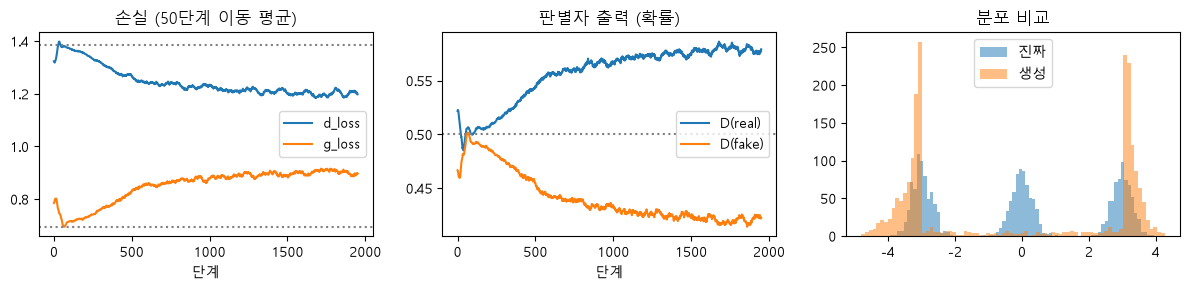

In [5]:
# [보강] 1차원 GAN 학습 2000단계 · 손실과 D 출력 기록
def train_1d(steps=2000):
    set_seed()
    G, D = mlp(Z1, 1, nn.Tanh()), mlp(1, 1, nn.LeakyReLU(0.2))
    G, D = G.to(device), D.to(device)
    og = torch.optim.Adam(G.parameters(), lr=2e-3, betas=(0.5, 0.999))
    od = torch.optim.Adam(D.parameters(), lr=2e-3, betas=(0.5, 0.999))
    gen = torch.Generator().manual_seed(SEED)
    one = torch.ones(64, 1, device=device)
    hist = {"d_loss": [], "g_loss": [], "D(real)": [], "D(fake)": []}
    for step in range(steps):
        real = real_1d(64, gen).to(device)
        fake = G(torch.randn(64, Z1, generator=gen).to(device))
        out_r, out_f = D(real), D(fake.detach())
        d_loss = bce(out_r, one) + bce(out_f, 0 * one)
        od.zero_grad()
        d_loss.backward()
        od.step()
        g_loss = bce(D(fake), one)
        og.zero_grad()
        g_loss.backward()
        og.step()
        for k, v in zip(hist, [d_loss, g_loss, torch.sigmoid(out_r).mean(),
                               torch.sigmoid(out_f).mean()]):
            hist[k].append(v.item())
    return G, hist


G1, hist1 = train_1d()
for k, v in hist1.items():  # 처음 50단계 평균 → 마지막 200단계 평균
    print(f"{k:7}: {np.mean(v[:50]):.4f} → {np.mean(v[-200:]):.4f}")


# 생성 2000개가 각 봉우리(중심 ± 0.9)에 몇 %씩 갔나
with torch.no_grad():
    sample = G1(torch.randn(2000, Z1, generator=gen).to(device)).cpu()[:, 0]
share = [((sample - m).abs() < 0.9).float().mean().item() for m in MODES_1D]
print("봉우리별 비율:", [round(s, 3) for s in share])


# 손실 곡선 · 진짜와 생성 분포
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for k in ["d_loss", "g_loss"]:
    ax[0].plot(np.convolve(hist1[k], np.ones(50) / 50, "valid"), label=k)
ax[0].axhline(2 * np.log(2), ls=":", c="gray")
ax[0].axhline(np.log(2), ls=":", c="gray")
ax[0].set_title("손실 (50단계 이동 평균)")
ax[0].legend()
for k in ["D(real)", "D(fake)"]:
    ax[1].plot(np.convolve(hist1[k], np.ones(50) / 50, "valid"), label=k)
ax[1].axhline(0.5, ls=":", c="gray")
ax[1].set_title("판별자 출력 (확률)")
ax[1].legend()
ax[2].hist(real_1d(2000, gen)[:, 0], bins=80, alpha=0.5, label="진짜")
ax[2].hist(sample, bins=80, alpha=0.5, label="생성")
ax[2].set_title("분포 비교")
ax[2].legend()
ax[0].set_xlabel("단계")
ax[1].set_xlabel("단계")
plt.tight_layout()
plt.show()

**예측 정답** · 아님 — 양쪽 봉우리 43%씩, 가운데 봉우리는 3%뿐 (손실은 정상처럼 보여도 봉우리 하나를 거의 놓침)

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>d_loss : 1.3232 → 1.2038</code></td>
<td style="text-align: left;">1.386(2·ln2) 근처에서 조금 아래 → 판별자가 약간 앞섬</td>
</tr>
<tr>
<td style="text-align: left;"><code>g_loss : 0.7851 → 0.9013</code></td>
<td style="text-align: left;">0.693(ln2)보다 조금 위, 줄다리기 중</td>
</tr>
<tr>
<td style="text-align: left;"><code>D(real): 0.5218 → 0.5785</code></td>
<td style="text-align: left;">진짜를 진짜라고 할 확률이 0.5보다 약간 높음</td>
</tr>
<tr>
<td style="text-align: left;"><code>D(fake): 0.4666 → 0.4215</code></td>
<td style="text-align: left;">가짜는 0.5보다 약간 낮음 → 아직 완전히 속이지 못함</td>
</tr>
<tr>
<td style="text-align: left;"><code>봉우리별 비율: [0.431, 0.03, 0.432]</code></td>
<td style="text-align: left;">가운데 봉우리(0)가 거의 빠짐 = 부분 모드 붕괴 (2장)</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">d_loss가 1.386 근처 · D(real) · D(fake)가 0.5 근처</td>
<td style="text-align: left;">판별자가 반반으로 헷갈림</td>
<td style="text-align: left;">균형이 맞는 정상 학습</td>
</tr>
<tr>
<td style="text-align: left;">d_loss → 0 · g_loss 계속 증가</td>
<td style="text-align: left;">판별자가 압도 (2-1 D 강함)</td>
<td style="text-align: left;">D lr · 갱신 횟수 줄이기</td>
</tr>
<tr>
<td style="text-align: left;">d_loss가 처음 값에서 안 변함</td>
<td style="text-align: left;">판별자가 배우지 못함 (2-1 D 약함)</td>
<td style="text-align: left;">D lr 올리기</td>
</tr>
<tr>
<td style="text-align: left;">손실은 정상인데 샘플이 비슷</td>
<td style="text-align: left;">모드 붕괴 가능 (2-2)</td>
<td style="text-align: left;">샘플 그림 · 다양성 수치 확인</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · GAN 손실이 내려가지 않는다고 학습 실패로 판단하거나, 손실이 안정적이라고 성공으로 판단하기 — 반드시 샘플 · 분포를 함께 확인

> ✅ **한 줄 정리** · GAN의 손실은 두 신경망의 상대적인 줄다리기라 균형점(d_loss ≈ 1.386, g_loss ≈ 0.693) 근처에서 흔들리는 것이 정상이며, 품질은 생성 결과를 직접 봐야 판단할 수 있다.

**딥러닝 코드에서는** · 학습 중 `d_loss` · `g_loss` · `D(real)` · `D(fake)`를 함께 기록하고, 고정 z로 만든 샘플 그림을 epoch마다 저장 (4장)

#### 1장 정리 · 소속별 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>nn.BCEWithLogitsLoss()</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">로짓 + 이진 교차 엔트로피 (판별자 · 생성자 손실)</td>
</tr>
<tr>
<td style="text-align: left;"><code>fake.detach()</code></td>
<td style="text-align: left;">torch.Tensor</td>
<td style="text-align: left;">판별자 갱신 때 생성자로 가는 기울기 끊기</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.optim.Adam(betas=(0.5, 0.999))</code></td>
<td style="text-align: left;">torch.optim</td>
<td style="text-align: left;">GAN 관례 설정 (모멘텀 작게)</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.sigmoid(D(x))</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">로짓 → 진짜일 확률</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.logit()</code> · <code>.backward()</code> · <code>.grad</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">확률 → 로짓, 기울기 크기 확인</td>
</tr>
</tbody>
</table>

---
## 2. 학습 균형 · 모드 붕괴

> **연결** · 1장 1차원 GAN은 손실이 정상이었는데 가운데 봉우리를 놓쳤다 → 봉우리 8개 2차원 데이터에서 균형이 깨질 때 · 생성자가 앞서 나갈 때의 무너짐을 일부러 만들고 진단 · 대응

**흐름 위치** · 학습 진단 — 손실 곡선, 샘플 그림, 다양성 수치, 대응 장치

### 2-1. `A` 판별자가 너무 강함 vs 너무 약함 · `d_steps` · `lr_d` <sub>개념 위클리 9 Q3 · 위클리 11 대응 기법 · 코드 보강</sub>

> 🎯 **판별자가 생성자보다 너무 강하거나 너무 약하면 손실과 생성 결과는 어떻게 달라지는가?**

💡 **쉽게 말하면** 감별사가 **너무 뛰어나면** 위조범은 뭘 고쳐야 할지 모른 채 몇 가지 무난한 위조만 반복하고, **너무 엉터리면** 위조범은 아무렇게나 만들어도 통과라 실력이 늘지 않음.

**실행 흐름** · 봉우리 8개 2차원 데이터 → 학습 · 점검 함수 → 기준(1:1) · D 강함(5번씩 · lr 5배) · D 약함(lr 1/100) → 마지막 300단계 손실 · 품질 · 잡은 봉우리

**먼저 예측** · 판별자가 강하면 생성 샘플의 품질(봉우리 근처 비율)은 떨어질까? — 답은 코드 실행 결과 아래에

In [6]:
# [보강] 2차원 진짜 데이터: 반지름 2 원 위 봉우리 8개 (표준편차 0.1)
ang = torch.arange(8) * (2 * np.pi / 8)
CENTERS = torch.stack([2 * torch.cos(ang), 2 * torch.sin(ang)], dim=1)


def real_2d(n, gen):
    k = torch.randint(0, 8, (n,), generator=gen)
    return CENTERS[k] + 0.1 * torch.randn(n, 2, generator=gen)


class MinibatchStdDev(nn.Module):  # 2-3에서 사용: 배치 다양성을 특징 1개로
    def forward(self, h):
        s = h.std(dim=0, unbiased=False).mean()  # 샘플 간 표준편차의 평균
        return torch.cat([h, s.expand(h.shape[0], 1)], dim=1)


def make_d(mbstd=False):
    act = nn.LeakyReLU(0.2)
    layers = [nn.Linear(2, 64), act, nn.Linear(64, 64), act]
    if mbstd:
        layers += [MinibatchStdDev(), nn.Linear(65, 1)]
    else:
        layers += [nn.Linear(64, 1)]
    return nn.Sequential(*layers)


def train_2d(d_steps=1, g_steps=1, lr_d=1e-3, lr_g=1e-3, mbstd=False,
             steps=3000):
    set_seed()
    G = mlp(2, 2, nn.ReLU(), hidden=64).to(device)
    D = make_d(mbstd).to(device)
    og = torch.optim.Adam(G.parameters(), lr=lr_g, betas=(0.5, 0.999))
    od = torch.optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))
    gen = torch.Generator().manual_seed(SEED)
    one = torch.ones(64, 1, device=device)
    hist = {"d_loss": [], "g_loss": []}
    for step in range(steps):
        for _ in range(d_steps):  # 판별자 d_steps번
            real = real_2d(64, gen).to(device)
            fake = G(torch.randn(64, 2, generator=gen).to(device)).detach()
            d_loss = bce(D(real), one) + bce(D(fake), 0 * one)
            od.zero_grad()
            d_loss.backward()
            od.step()
        for _ in range(g_steps):  # 생성자 g_steps번
            fake = G(torch.randn(64, 2, generator=gen).to(device))
            g_loss = bce(D(fake), one)
            og.zero_grad()
            g_loss.backward()
            og.step()
        hist["d_loss"].append(d_loss.item())
        hist["g_loss"].append(g_loss.item())
    return G, hist


@torch.no_grad()
def check_2d(G, n=2000):  # 품질 · 잡은 봉우리 · 배치 다양성
    gen = torch.Generator().manual_seed(0)
    x = G(torch.randn(n, 2, generator=gen).to(device)).cpu()
    dist, k = torch.cdist(x, CENTERS).min(dim=1)  # 가장 가까운 봉우리
    good = dist < 0.3  # 봉우리 중심 0.3 이내 = 그럴듯한 샘플
    modes = int((torch.bincount(k[good], minlength=8) >= 50).sum())
    spread = torch.pdist(x[:500]).mean().item()  # 샘플끼리 평균 거리
    return x, dict(quality=good.float().mean().item(), modes=modes,
                   spread=spread)


# 기준 · 판별자 강함(5번씩 · 큰 lr) · 판별자 약함(아주 작은 lr)
runs_21 = {"기준 1:1": dict(),
           "D 강함": dict(d_steps=5, lr_d=5e-3),
           "D 약함": dict(lr_d=1e-5)}
res_21 = {}
for name, cfg in runs_21.items():
    G, hist = train_2d(**cfg)
    x, m = check_2d(G)
    res_21[name] = (x, hist)
    print(f"{name:7} | d_loss {np.mean(hist['d_loss'][-300:]):.4f}"
          f" | g_loss {np.mean(hist['g_loss'][-300:]):.4f}"
          f" | 품질 {m['quality']:.3f} | 봉우리 {m['modes']}/8")

기준 1:1  | d_loss 1.3664 | g_loss 0.7370 | 품질 0.863 | 봉우리 8/8


D 강함    | d_loss 0.7161 | g_loss 1.5883 | 품질 0.900 | 봉우리 3/8


D 약함    | d_loss 1.3876 | g_loss 0.7352 | 품질 0.000 | 봉우리 0/8


**예측 정답** · 아님 — 품질은 0.900으로 오히려 높지만 봉우리를 3개만 잡음 (확실한 곳만 만들기)

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>기준 1:1  &#124; d&#95;loss 1.3664 &#124; g&#95;loss 0.7370 &#124; 품질 0.863 &#124; 봉우리 8/8</code></td>
<td style="text-align: left;">균형점 근처, 8개 봉우리를 모두 덮음</td>
</tr>
<tr>
<td style="text-align: left;"><code>D 강함    &#124; d&#95;loss 0.7161 &#124; g&#95;loss 1.5883 &#124; 품질 0.900 &#124; 봉우리 3/8</code></td>
<td style="text-align: left;">d_loss가 크게 낮고 g_loss가 높음 → D가 압도, 다양성 손실</td>
</tr>
<tr>
<td style="text-align: left;"><code>D 약함    &#124; d&#95;loss 1.3876 &#124; g&#95;loss 0.7352 &#124; 품질 0.000 &#124; 봉우리 0/8</code></td>
<td style="text-align: left;">손실은 균형점과 같아 보이지만 D가 배우지 못해 G도 엉뚱한 곳</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">판별자 너무 강함</td>
<td style="text-align: left;">가짜를 쉽게 가려내 D 출력이 0에 붙음 → G가 받는 신호가 들쭉날쭉</td>
<td style="text-align: left;">D 갱신 횟수 · lr 줄이기, 정규화(Spectral Norm · R1)</td>
</tr>
<tr>
<td style="text-align: left;">판별자 너무 약함</td>
<td style="text-align: left;">진짜 · 가짜를 못 가려 G에게 쓸모 있는 방향을 못 줌</td>
<td style="text-align: left;">D lr 올리기 · D 키우기</td>
</tr>
<tr>
<td style="text-align: left;">균형 (1:1 · 같은 lr)</td>
<td style="text-align: left;">서로 따라잡으며 둘 다 배움</td>
<td style="text-align: left;">출발점, 이후 TTUR(D lr 4배) 등으로 조정</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · "D 약함"의 손실은 기준과 거의 같음 (1.3876 vs 1.3664) → 손실 숫자만으로는 정상과 구분 불가, 샘플을 그려야 보임

> ✅ **한 줄 정리** · 판별자가 너무 강하면 생성자는 확실한 몇 곳에만 몰리고, 너무 약하면 학습 신호가 없어 아무것도 배우지 못하므로 두 신경망의 균형을 맞춰야 한다.

**딥러닝 코드에서는** · 균형 조정 손잡이: 갱신 비(D:G), 학습률(TTUR: D 4e-4 · G 1e-4), 정규화(Spectral Norm · R1) — 한 번에 하나씩 바꾸며 비교 (위클리 11)

### 2-2. `A` 모드 붕괴 만들기와 진단 · `g_steps=5` · `pdist` <sub>개념 위클리 11 · 코드 보강</sub>

> 🎯 **생성자를 판별자보다 너무 자주 갱신하면 어떤 일이 생기고, 그것을 숫자로 어떻게 알아보는가?**

💡 **쉽게 말하면** 위조범이 감별사보다 5배 빨리 연습하면 **지금 감별사가 가장 잘 속는 위조 하나**만 계속 찍어 냄. 손님(z)이 누구든 같은 지폐를 건네는 상태 = **모드 붕괴**.

**실행 흐름** · G 5번 : D 1번 학습 → 정상과 품질 · 봉우리 · 배치 다양성 비교 → 서로 다른 z 5개의 출력 → 진짜 데이터의 배치 다양성(기준)

**먼저 예측** · 생성자를 5배 자주 갱신하면 서로 다른 z 5개의 출력은 얼마나 다를까? — 답은 코드 실행 결과 아래에

In [7]:
# [보강] 모드 붕괴를 일부러: 생성자를 판별자보다 5배 자주 갱신
G_c, hist_c = train_2d(g_steps=5)
x_c, m_c = check_2d(G_c)
x_n, m_n = check_2d(train_2d()[0])  # 기준(1:1) 다시 학습 → 같은 결과
for name, m in [("정상 1:1", m_n), ("붕괴 1:5", m_c)]:
    print(f"{name} | 품질 {m['quality']:.3f} | 봉우리 {m['modes']}/8"
          f" | 배치 다양성(평균 거리) {m['spread']:.4f}")


# 진단 1: 서로 다른 z 5개 → 출력이 얼마나 다른가
z5 = torch.randn(5, 2, generator=torch.Generator().manual_seed(1))
with torch.no_grad():
    out = G_c(z5.to(device)).cpu()
print("붕괴 G의 z 5개 출력:", [[round(v, 2) for v in r] for r in out.tolist()])


# 진단 2: 진짜 데이터 사이 평균 거리 (다양성의 기준)
real = real_2d(500, torch.Generator().manual_seed(0))
print("진짜 데이터 배치 다양성:", round(torch.pdist(real).mean().item(), 4))

정상 1:1 | 품질 0.863 | 봉우리 8/8 | 배치 다양성(평균 거리) 2.5664
붕괴 1:5 | 품질 0.377 | 봉우리 1/8 | 배치 다양성(평균 거리) 0.1749
붕괴 G의 z 5개 출력: [[1.13, 1.2], [1.06, 1.14], [1.14, 1.19], [1.15, 1.2], [1.18, 1.18]]
진짜 데이터 배치 다양성: 2.5395


**예측 정답** · 거의 같음 — 모두 (1.1, 1.2) 근처 한 점, 배치 다양성 0.1749 (진짜는 2.5395)

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>정상 1:1 &#124; 품질 0.863 &#124; 봉우리 8/8 &#124; 배치 다양성(평균 거리) 2.5664</code></td>
<td style="text-align: left;">진짜 데이터(2.5395)와 비슷한 퍼짐</td>
</tr>
<tr>
<td style="text-align: left;"><code>붕괴 1:5 &#124; 품질 0.377 &#124; 봉우리 1/8 &#124; 배치 다양성(평균 거리) 0.1749</code></td>
<td style="text-align: left;">봉우리 1개 · 다양성이 진짜의 7% → 완전 붕괴에 가까움</td>
</tr>
<tr>
<td style="text-align: left;"><code>붕괴 G의 z 5개 출력: [[1.13, 1.2], [1.06, 1.14], [1.14, 1.19], [1.15, 1.2], [1.18, 1.18]]</code></td>
<td style="text-align: left;">z가 달라도 출력이 거의 같음 → 생성자가 z를 무시</td>
</tr>
<tr>
<td style="text-align: left;"><code>진짜 데이터 배치 다양성: 2.5395</code></td>
<td style="text-align: left;">다양성 수치의 기준값</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">정상</td>
<td style="text-align: left;">z가 다르면 출력도 다름, 봉우리 8개를 모두 덮음</td>
<td style="text-align: left;">목표 상태</td>
</tr>
<tr>
<td style="text-align: left;">완전 붕괴</td>
<td style="text-align: left;">모든 z가 거의 한 점 → 배치 다양성이 0에 가까움</td>
<td style="text-align: left;">z 5개 출력 비교 · 배치 평균 거리로 바로 보임</td>
</tr>
<tr>
<td style="text-align: left;">부분 붕괴 (모드 누락)</td>
<td style="text-align: left;">여러 종류지만 일부 봉우리(숫자)가 없음</td>
<td style="text-align: left;">분류기로 종류 분포를 세야 보임 (4장 MNIST)</td>
</tr>
<tr>
<td style="text-align: left;">모드 호핑</td>
<td style="text-align: left;">학습 시점마다 쏠리는 종류가 통째로 바뀜</td>
<td style="text-align: left;">고정 z 격자를 시점별로 비교 (4장)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 첫 단계부터 출력이 비슷하면 붕괴보다 **구현 오류**(z를 루프 밖에서 한 번만 뽑음 · 같은 배치 반복)를 먼저 의심 (위클리 11 진단표)

> ✅ **한 줄 정리** · 모드 붕괴는 z가 달라도 출력이 몇 가지로 몰리는 현상이며, 배치 안 샘플 간 평균 거리 같은 다양성 수치를 진짜 데이터와 비교해 알아본다.

**딥러닝 코드에서는** · 학습 중 `torch.pdist(G(z).flatten(1)).mean()`을 기록 → 계속 줄면 경고, 고정 z 격자 그림을 epoch마다 저장해 나란히 비교

### 2-3. `B` 대응: Minibatch StdDev · `MinibatchStdDev` <sub>개념 위클리 11 대응 기법 · 코드 보강</sub>

> 🎯 **판별자에 배치 다양성을 보여 주면, 같은 붕괴 설정에서도 생성자가 다시 다양해지는가?**

💡 **쉽게 말하면** 감별사에게 **한 번에 여러 장을 보여 주고 "이 묶음이 다 비슷한가"도 보게** 하면, 같은 위조만 반복하는 위조범은 바로 들킴.

**실행 흐름** · 붕괴 설정(1:5) 그대로 판별자에 MinibatchStdDev 추가 → 품질 · 봉우리 · 다양성 → 다양한 배치 · 같은 점 배치에서 붙는 특징 값 → 다섯 실험 산점도

**먼저 예측** · 붕괴 설정은 그대로 두고 판별자에 장치 하나만 넣어도 봉우리를 되찾을까? — 답은 코드 실행 결과 아래에

붕괴 1:5 + MinibatchStdDev | 품질 0.910 | 봉우리 8/8 | 배치 다양성 2.4728
붙는 특징 · 다양한 배치: 1.4172 | 같은 점 배치: 0.0


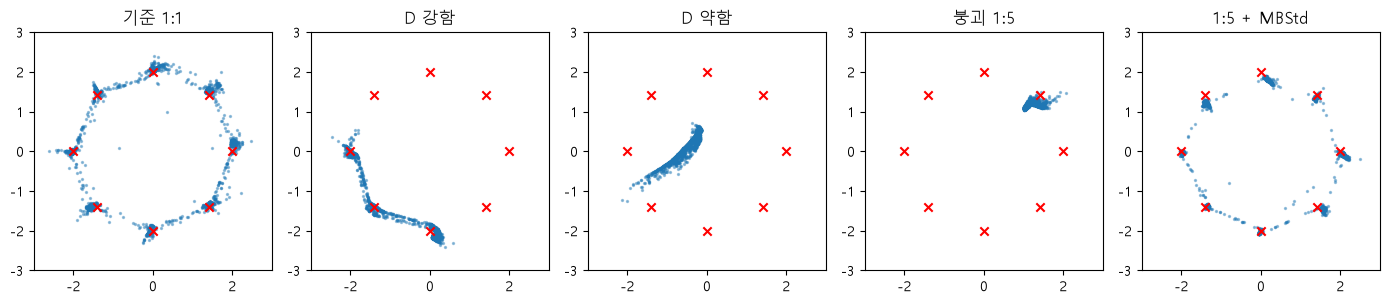

In [8]:
# [보강] 대응: 판별자에 Minibatch StdDev → 배치가 단조로우면 가짜로 알아봄
G_m, hist_m = train_2d(g_steps=5, mbstd=True)  # 붕괴 설정 그대로 + 장치
x_m, m_m = check_2d(G_m)
print(f"붕괴 1:5 + MinibatchStdDev | 품질 {m_m['quality']:.3f}"
      f" | 봉우리 {m_m['modes']}/8 | 배치 다양성 {m_m['spread']:.4f}")


# 같은 배치 통계를 다양한 배치 · 단조로운 배치에서 비교
layer = MinibatchStdDev()
varied = real_2d(64, torch.Generator().manual_seed(0))
same = varied[:1].repeat(64, 1)  # 한 점만 64번
print("붙는 특징 · 다양한 배치:", round(layer(varied)[0, -1].item(), 4),
      "| 같은 점 배치:", round(layer(same)[0, -1].item(), 4))


# 기준 · D 강함 · D 약함 · 붕괴 · 대응 산점도
panels = [(res_21[k][0], k) for k in runs_21] + [(x_c, "붕괴 1:5"),
                                                 (x_m, "1:5 + MBStd")]
fig, ax = plt.subplots(1, 5, figsize=(14, 2.9))
for a, (x, title) in zip(ax, panels):
    a.scatter(x[:, 0], x[:, 1], s=2, alpha=0.4)
    a.scatter(CENTERS[:, 0], CENTERS[:, 1], c="red", marker="x")
    a.set_title(title)
    a.set_xlim(-3, 3)
    a.set_ylim(-3, 3)
    a.set_aspect("equal")
plt.tight_layout()
plt.show()

**예측 정답** · 되찾음 — 1/8 → 8/8, 배치 다양성 0.1749 → 2.4728

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>붕괴 1:5 + MinibatchStdDev &#124; 품질 0.910 &#124; 봉우리 8/8 &#124; 배치 다양성 2.4728</code></td>
<td style="text-align: left;">같은 1:5인데 정상보다 품질까지 높음</td>
</tr>
<tr>
<td style="text-align: left;"><code>붙는 특징 · 다양한 배치: 1.4172 &#124; 같은 점 배치: 0.0</code></td>
<td style="text-align: left;">단조로운 배치는 이 특징이 0 → 판별자가 "가짜 묶음"으로 바로 알아봄</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">Minibatch StdDev</td>
<td style="text-align: left;">판별자가 배치 안 샘플 간 표준편차를 특징으로 봄 → 단조로운 배치를 가짜로</td>
<td style="text-align: left;">모드 붕괴 대응의 첫 시도, 비용 거의 없음 (ProGAN · StyleGAN)</td>
</tr>
<tr>
<td style="text-align: left;">D:G 갱신 비 조정</td>
<td style="text-align: left;">한쪽이 앞서 나가지 않게 균형 (이 실험의 원인 제거)</td>
<td style="text-align: left;">생성자 과학습이 원인일 때</td>
</tr>
<tr>
<td style="text-align: left;">WGAN-GP · Spectral Norm</td>
<td style="text-align: left;">손실 · 정규화를 바꿔 기울기를 안정화</td>
<td style="text-align: left;">모델이 크고 학습이 자주 흔들릴 때 (위클리 11 표)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · Minibatch StdDev는 판별자의 **입력이 아니라 마지막 층 직전 특징**에 붙임 (위클리 11 정정), 배치가 너무 작으면 표준편차가 흔들림

> ✅ **한 줄 정리** · 판별자가 배치 안 샘플 간 다양성을 특징으로 보게 하면, 생성자는 한 가지만 반복해서는 속일 수 없어 모드 붕괴가 줄어든다.

**딥러닝 코드에서는** · StyleGAN 판별자 마지막 블록의 `MinibatchStdDev(group_size=4)` — 원인이 여러 겹이라 점검 → 균형 → 손실 · 정규화 → 다양성 장치 순서로 하나씩 (위클리 11)

#### 2장 정리 · 소속별 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>train_2d(d_steps, g_steps, lr_d, mbstd)</code></td>
<td style="text-align: left;">보강 함수</td>
<td style="text-align: left;">균형 · 장치만 바꿔 같은 조건 학습</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.cdist(x, centers).min(dim=1)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">가장 가까운 봉우리 · 거리 (품질 · 봉우리 수)</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.pdist(x).mean()</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">배치 안 샘플끼리 평균 거리 (다양성)</td>
</tr>
<tr>
<td style="text-align: left;"><code>MinibatchStdDev</code></td>
<td style="text-align: left;">보강 모듈 (ProGAN 방식)</td>
<td style="text-align: left;">배치 표준편차를 판별자 특징으로</td>
</tr>
</tbody>
</table>

---
## 3. Diffusion

> **연결** · 2장 GAN은 두 신경망의 경쟁이라 균형이 깨지면 무너졌다 → Diffusion은 경쟁 없이 "넣은 노이즈를 맞히는" 회귀 문제 하나로 바꿔 안정적으로 학습

**흐름 위치** · 생성 모델 비교 — 전방향(정해진 노이즈) · 역방향(학습한 예측으로 생성)

### 3-1. `A` Diffusion 전방향: 노이즈 더하기 · `ᾱ_t` · `add_noise` <sub>개념 위클리 9 Q4 · 코드 보강</sub>

> 🎯 **Diffusion의 전방향 과정은 데이터에 노이즈를 어떤 비율로 더하며, 마지막에는 무엇이 남는가?**

💡 **쉽게 말하면** 사진 위에 **모래를 조금씩 1000번 뿌리는 것**. 몇 번 뿌리면 윤곽이 보이지만 1000번 뒤에는 **모래(노이즈)만** 남음. 뿌리는 양은 미리 정해 둔 규칙이라 학습이 필요 없음.

**실행 흐름** · β 일정 → ᾱ_t 누적 곱 → t별 원본 비중 · 노이즈 비중 → MNIST 숫자 · 2차원 점에 t = 0 · 50 · 200 · 500 · 999 노이즈 → x_T 평균 · 표준편차

**먼저 예측** · t = 500(절반)이면 원본 비중 √ᾱ는 0.5 근처일까? — 답은 코드 실행 결과 아래에

t=  0 | √ᾱ(원본 비중) 0.9999 | √(1-ᾱ)(노이즈 비중) 0.0100
t= 50 | √ᾱ(원본 비중) 0.9849 | √(1-ᾱ)(노이즈 비중) 0.1733
t=200 | √ᾱ(원본 비중) 0.8102 | √(1-ᾱ)(노이즈 비중) 0.5862
t=500 | √ᾱ(원본 비중) 0.2789 | √(1-ᾱ)(노이즈 비중) 0.9603
t=999 | √ᾱ(원본 비중) 0.0064 | √(1-ᾱ)(노이즈 비중) 1.0000


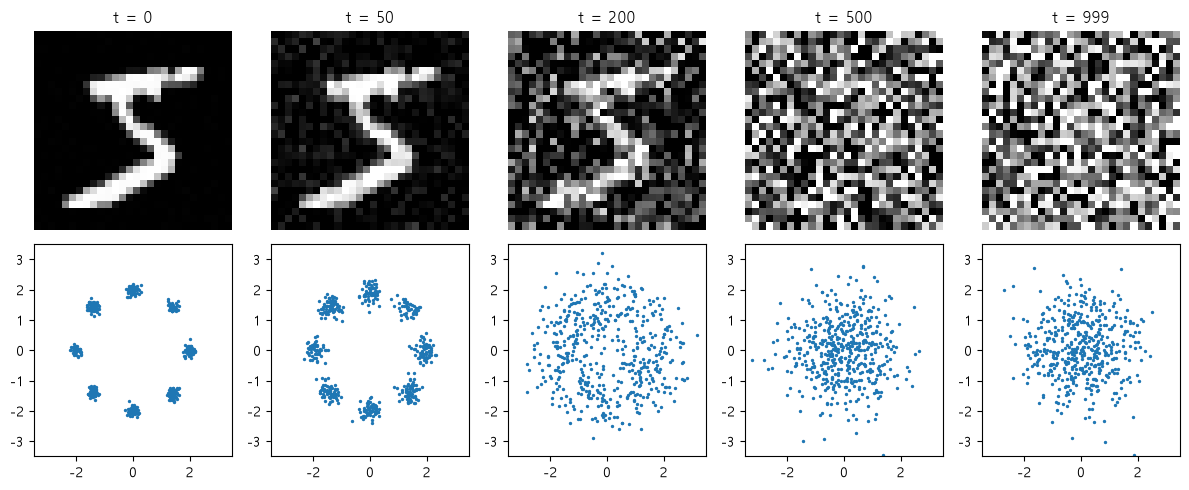

x_T 평균: [-0.058, -0.024] | 표준편차: [0.914, 0.969]


In [9]:
# [보강] 노이즈 일정 (DDPM): β를 0.0001 → 0.02로 1000단계
T = 1000
betas = torch.linspace(1e-4, 0.02, T)
alphas = 1 - betas
abar = torch.cumprod(alphas, dim=0)  # ᾱ_t = (1-β_1)(1-β_2)…(1-β_t)


def add_noise(x0, t, gen):  # x_t = √ᾱ_t · x0 + √(1-ᾱ_t) · ε (한 번에)
    eps = torch.randn(x0.shape, generator=gen)
    return abar[t].sqrt() * x0 + (1 - abar[t]).sqrt() * eps


show_t = [0, 50, 200, 500, 999]
for t in show_t:
    print(f"t={t:3} | √ᾱ(원본 비중) {abar[t].sqrt():.4f}"
          f" | √(1-ᾱ)(노이즈 비중) {(1 - abar[t]).sqrt():.4f}")


# MNIST 숫자 1장과 2차원 데이터에 단계별로 노이즈 더하기
gen = torch.Generator().manual_seed(SEED)
digit = X_mnist[0].view(28, 28)  # -1 ~ 1
pts = real_2d(500, gen)
fig, ax = plt.subplots(2, len(show_t), figsize=(12, 5))
for c, t in enumerate(show_t):
    ax[0, c].imshow(add_noise(digit, t, gen), cmap="gray", vmin=-1, vmax=1)
    xt = add_noise(pts, t, gen)
    ax[1, c].scatter(xt[:, 0], xt[:, 1], s=2)
    ax[1, c].set_xlim(-3.5, 3.5)
    ax[1, c].set_ylim(-3.5, 3.5)
    ax[0, c].set_title(f"t = {t}")
    ax[0, c].axis("off")
plt.tight_layout()
plt.show()


# 마지막 x_T는 거의 표준 정규분포
xT = add_noise(pts, T - 1, gen)
print("x_T 평균:", [round(v, 3) for v in xT.mean(0).tolist()],
      "| 표준편차:", [round(v, 3) for v in xT.std(0).tolist()])

**예측 정답** · 아님 — 0.2789, β가 뒤로 갈수록 커져서 절반 지점에 이미 원본이 많이 사라짐

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>t=  0 &#124; √ᾱ(원본 비중) 0.9999 &#124; √(1-ᾱ)(노이즈 비중) 0.0100</code></td>
<td style="text-align: left;">첫 단계는 노이즈가 아주 조금</td>
</tr>
<tr>
<td style="text-align: left;"><code>t=200 &#124; √ᾱ(원본 비중) 0.8102 &#124; √(1-ᾱ)(노이즈 비중) 0.5862</code></td>
<td style="text-align: left;">숫자 모양은 아직 보임</td>
</tr>
<tr>
<td style="text-align: left;"><code>t=500 &#124; √ᾱ(원본 비중) 0.2789 &#124; √(1-ᾱ)(노이즈 비중) 0.9603</code></td>
<td style="text-align: left;">노이즈가 대부분</td>
</tr>
<tr>
<td style="text-align: left;"><code>t=999 &#124; √ᾱ(원본 비중) 0.0064 &#124; √(1-ᾱ)(노이즈 비중) 1.0000</code></td>
<td style="text-align: left;">원본은 거의 0 → 순수한 노이즈</td>
</tr>
<tr>
<td style="text-align: left;"><code>x&#95;T 평균: [-0.058, -0.024] &#124; 표준편차: [0.914, 0.969]</code></td>
<td style="text-align: left;">평균 0 · 표준편차 1 근처 = 표준 정규분포 → 생성은 여기서 출발</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">전방향 (노이즈 더하기)</td>
<td style="text-align: left;">정해진 식, 학습 없음, x0에서 x_t를 한 번에 계산</td>
<td style="text-align: left;">학습 데이터 만들기 (시점 t 무작위)</td>
</tr>
<tr>
<td style="text-align: left;">√ᾱ_t · √(1-ᾱ_t)</td>
<td style="text-align: left;">원본 비중 · 노이즈 비중, t가 클수록 원본이 사라짐</td>
<td style="text-align: left;">노이즈 일정 설계 (선형 · cosine)</td>
</tr>
<tr>
<td style="text-align: left;">오토인코더의 노이즈 제거</td>
<td style="text-align: left;">노이즈 1단계를 한 번에 복원 (오토인코더-2 참조)</td>
<td style="text-align: left;">복원 · 이상 탐지 (생성 X)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · x_t를 만들 때 1단계부터 t단계까지 반복할 필요 없음 — 식 하나로 x0에서 바로 계산 (그래서 학습 때 t를 무작위로 골라도 빠름)

> ✅ **한 줄 정리** · Diffusion의 전방향은 정해진 일정에 따라 원본 비중 √ᾱ_t를 줄이고 노이즈 비중을 늘려, 마지막에는 표준 정규분포 노이즈만 남긴다.

**딥러닝 코드에서는** · 학습 한 단계: `t = torch.randint(0, T, (B,))` → `xt = add_noise(x0, t)` → `loss = F.mse_loss(model(xt, t), eps)` (넣은 노이즈 맞히기)

### 3-2. `B` Diffusion 역방향: 노이즈 빼며 생성 · `eps_star` · `1000단계` <sub>개념 위클리 9 Q4 실험 6 · 코드 보강</sub>

> 🎯 **순수한 노이즈에서 노이즈를 단계적으로 빼면 정말 데이터 분포가 나타나며, GAN과 비교해 무엇이 다른가?**

💡 **쉽게 말하면** 모래만 남은 판에서 **노이즈 예측기**("여기에 뿌려진 모래는 이만큼"을 맞히는 사람)가 있으면, 1000번에 걸쳐 조금씩 걷어 내 그림을 되살림. 매번 조금씩 무작위로 걷어 내서 **매번 다른 그림**이 나옴.

**실행 흐름** · 데이터가 봉우리 8개라 최적 노이즈 예측기 ε*를 식으로 계산 → N(0, I) 500개에서 1000단계 역방향 → 단계별 모습 · 품질 · 봉우리 · 봉우리별 개수

**먼저 예측** · 역방향 생성 결과는 GAN 붕괴처럼 일부 봉우리에 몰릴까? — 답은 코드 실행 결과 아래에

생성 500개 · 품질: 0.984 | 봉우리: 8 / 8 | 신경망 호출 수: 1000
봉우리별 개수: [62, 73, 53, 59, 69, 62, 62, 52]


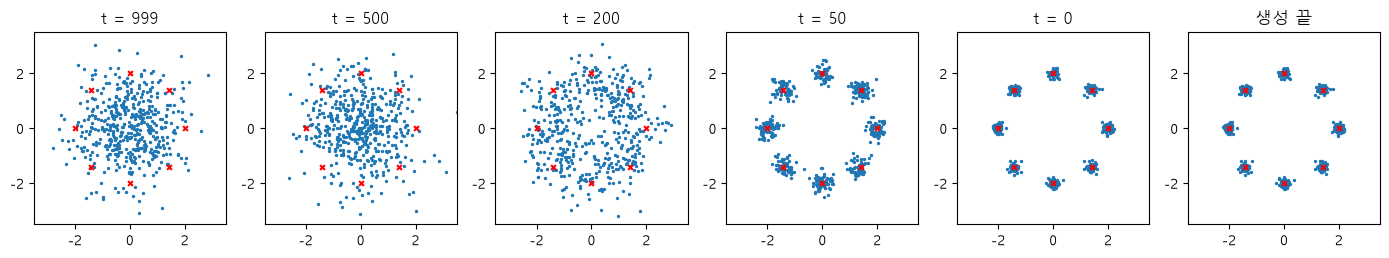

In [10]:
# [보강] 정확한 노이즈 예측기 ε*(x_t, t): 데이터가 봉우리 8개라 식으로 계산
#        (실제 Diffusion은 이 자리에 신경망을 MSE로 학습)
def eps_star(x, t):
    a = abar[t]
    var = a * 0.1 ** 2 + (1 - a)  # x_t의 봉우리별 분산
    mu = a.sqrt() * CENTERS  # x_t의 봉우리 중심
    d2 = ((x[:, None, :] - mu[None]) ** 2).sum(-1)  # (N, 8) 거리²
    w = torch.softmax(-d2 / (2 * var), dim=1)  # 어느 봉우리에서 왔을 확률
    score = (w[:, :, None] * (mu[None] - x[:, None, :])).sum(1) / var
    return -(1 - a).sqrt() * score  # score → 노이즈 예측


# 역방향: 순수 노이즈에서 출발해 1000단계 동안 노이즈를 조금씩 빼기
gen = torch.Generator().manual_seed(SEED)
x = torch.randn(500, 2, generator=gen)  # x_T ~ N(0, I)
snap = {}
for t in reversed(range(T)):
    if t in (999, 500, 200, 50, 0):
        snap[t] = x.clone()
    eps = eps_star(x, t)
    mean = (x - betas[t] / (1 - abar[t]).sqrt() * eps) / alphas[t].sqrt()
    noise = torch.randn(x.shape, generator=gen) if t > 0 else 0
    x = mean + betas[t].sqrt() * noise
dist, k = torch.cdist(x, CENTERS).min(dim=1)
good = dist < 0.3
print("생성 500개 · 품질:", round(good.float().mean().item(), 3),
      "| 봉우리:", int((torch.bincount(k[good], minlength=8) >= 20).sum()),
      "/ 8 | 신경망 호출 수:", T)
print("봉우리별 개수:", torch.bincount(k[good], minlength=8).tolist())


fig, ax = plt.subplots(1, len(snap) + 1, figsize=(14, 2.6))
for a, (t, s) in zip(ax, list(snap.items()) + [("생성 끝", x)]):
    a.scatter(s[:, 0], s[:, 1], s=2)
    a.scatter(CENTERS[:, 0], CENTERS[:, 1], c="red", marker="x", s=12)
    a.set_title(f"t = {t}" if t != "생성 끝" else t)
    a.set_xlim(-3.5, 3.5)
    a.set_ylim(-3.5, 3.5)
    a.set_aspect("equal")
plt.tight_layout()
plt.show()

**예측 정답** · 아님 — 8개 봉우리에 52 ~ 73개씩 고르게, 품질 0.984

**결과 해설**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>생성 500개 · 품질: 0.984 &#124; 봉우리: 8 / 8 &#124; 신경망 호출 수: 1000</code></td>
<td style="text-align: left;">모든 봉우리 · 높은 품질, 대신 샘플 하나에 예측 1000번</td>
</tr>
<tr>
<td style="text-align: left;"><code>봉우리별 개수: [62, 73, 53, 59, 69, 62, 62, 52]</code></td>
<td style="text-align: left;">고르면 봉우리마다 약 62개 → 쏠림 없음</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">오토인코더 (VAE)</td>
<td style="text-align: left;">인코더 → 잠재 → 디코더, 재구성 + KL, 디코더 1번에 생성</td>
<td style="text-align: left;">안정적 · 빠름, 흐릿해지기 쉬움 (오토인코더-1 · 2)</td>
</tr>
<tr>
<td style="text-align: left;">GAN</td>
<td style="text-align: left;">생성자 vs 판별자 게임, 순전파 1번에 생성</td>
<td style="text-align: left;">선명 · 빠름, 균형 · 모드 붕괴 위험 (1 ~ 2장)</td>
</tr>
<tr>
<td style="text-align: left;">Diffusion</td>
<td style="text-align: left;">넣은 노이즈를 맞히는 MSE, 노이즈에서 수십 ~ 1000단계로 생성</td>
<td style="text-align: left;">품질 · 다양성 최고, 생성이 느림 (Stable Diffusion)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 이 셀의 ε*는 데이터 식을 아는 **정답 예측기**라 학습이 없음 — 실제로는 신경망을 MSE로 학습해 근사하며, 단계를 줄이면(DDIM 등) 빨라지는 대신 품질 관리가 필요

> ✅ **한 줄 정리** · Diffusion은 노이즈를 한 단계씩 빼는 역방향을 반복해 데이터 분포 전체에서 고르게 샘플을 만들지만, 샘플 하나에 신경망을 수십 ~ 1000번 호출해 느리다.

**딥러닝 코드에서는** · Stable Diffusion = 이 역방향을 오토인코더의 잠재 공간(64×64×4)에서 하고, 텍스트 조건을 cross-attention으로 넣은 것 (위클리 9 Q4 보충)

#### 3장 정리 · 소속별 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>torch.linspace(1e-4, 0.02, 1000)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">DDPM 노이즈 일정 β</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.cumprod(1 - betas, 0)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">ᾱ_t 누적 곱</td>
</tr>
<tr>
<td style="text-align: left;"><code>add_noise(x0, t)</code></td>
<td style="text-align: left;">보강 함수</td>
<td style="text-align: left;">x0에서 x_t를 한 번에</td>
</tr>
<tr>
<td style="text-align: left;"><code>eps_star(x, t)</code> · 역방향 반복</td>
<td style="text-align: left;">보강 함수</td>
<td style="text-align: left;">노이즈 예측 → 조금씩 빼기 (DDPM 샘플러)</td>
</tr>
</tbody>
</table>

---
## 4. 종합 실습 · MNIST 작은 GAN: 정상 vs 모드 붕괴

> **연결** · 1장 학습 단계 + 2장 균형 · 진단을 실제 이미지(MNIST 손글씨)에서. 2-2에서 2차원 점으로 만든 붕괴(생성자 1:5)를 이미지에서 다시 만들고, **숫자 분포 · 다양성 · 선명도** 세 지표로 비교

**흐름 위치** · 데이터 → 생성자 · 판별자 → 번갈아 학습 → 고정 z 격자 · 손실 곡선 → 평가 지표

> 🎯 **같은 MNIST GAN에서 생성자만 5배 자주 갱신하면 숫자 종류 · 다양성 · 선명도는 어떻게 달라지는가?**

💡 **쉽게 말하면** 생성 품질은 **얼마나 또렷한가**(선명도)와 **얼마나 여러 종류인가**(다양성 · 숫자 분포) 두 축. 숫자를 읽는 **평가용 분류기**로 생성 1000장이 어떤 숫자인지 세면 빠진 숫자(모드)가 보임.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">지표</th>
<th style="text-align: left;">계산</th>
<th style="text-align: left;">무엇을 보나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">숫자 종류</td>
<td style="text-align: left;">평가용 분류기 예측에서 3% 이상인 숫자 수 (10이 최대)</td>
<td style="text-align: left;">모드 누락 (Recall에 해당)</td>
</tr>
<tr>
<td style="text-align: left;">최다 몫</td>
<td style="text-align: left;">가장 많이 나온 숫자의 비율 (고르면 0.1)</td>
<td style="text-align: left;">쏠림 · 붕괴</td>
</tr>
<tr>
<td style="text-align: left;">다양성</td>
<td style="text-align: left;">생성 300장끼리 평균 거리</td>
<td style="text-align: left;">샘플이 서로 다른가</td>
</tr>
<tr>
<td style="text-align: left;">선명도</td>
<td style="text-align: left;">픽셀이 0.1 아래 · 0.9 위인 비율 (흐리면 중간 회색)</td>
<td style="text-align: left;">또렷한가 (Precision에 가까운 감각)</td>
</tr>
</tbody>
</table>

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">같은 조건</th>
<th style="text-align: left;">값</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">데이터 · 배치</td>
<td style="text-align: left;">MNIST 학습 60000장, 배치 128, 10 epoch</td>
</tr>
<tr>
<td style="text-align: left;">모델 · 최적화</td>
<td style="text-align: left;">MLP 생성자(z 64 → 784, Tanh) · MLP 판별자, Adam lr 0.0002 · β₁ 0.5</td>
</tr>
<tr>
<td style="text-align: left;">다른 점</td>
<td style="text-align: left;">판별자 1번당 생성자 1번(정상) vs 5번(생성자 과학습)</td>
</tr>
</tbody>
</table>

**먼저 예측** · 생성자 과학습 GAN의 첫 epoch 생성 1000장 중 가장 많은 숫자의 몫은? — 답은 코드 실행 결과 아래에

In [11]:
# [보강] 평가용 숫자 분류기: 생성 이미지가 어떤 숫자인지 세는 도구 (FID의 Inception 역할)
set_seed()
clf = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(32 * 7 * 7, 10)).to(device)
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
Xc = ((X_mnist + 1) / 2).view(-1, 1, 28, 28).to(device)  # 0 ~ 1 이미지
Yc = Y_mnist.to(device)
gen = torch.Generator().manual_seed(SEED)
for epoch in range(2):
    perm = torch.randperm(len(Xc), generator=gen).to(device)
    for i in range(0, len(Xc), 256):
        b = perm[i:i + 256]
        loss = F.cross_entropy(clf(Xc[b]), Yc[b])
        opt.zero_grad()
        loss.backward()
        opt.step()
test = torchvision.datasets.MNIST(DATA, train=False, download=True)
with torch.no_grad():
    x_te = (test.data.float() / 255)[:, None].to(device)
    acc = (clf(x_te).argmax(1).cpu() == test.targets).float().mean().item()
print(f"평가용 분류기 테스트 정확도: {acc:.4f}")


@torch.no_grad()
def quality(img):  # img: (N, 784), 0 ~ 1
    counts = torch.bincount(clf(img.view(-1, 1, 28, 28)).argmax(1).cpu(),
                            minlength=10)
    return dict(counts=counts.tolist(),
                kinds=int((counts >= 0.03 * len(img)).sum()),  # 3% 넘는 숫자
                top=counts.max().item() / len(img),  # 가장 많은 숫자 몫
                spread=torch.pdist(img[:300]).mean().item(),  # 다양성
                sharp=((img < 0.1) | (img > 0.9)).float().mean().item())  # 선명도


real_q = quality(((X_mnist[:1000] + 1) / 2).to(device))
print(f"진짜 1000장 기준 | 숫자 {real_q['kinds']}종 | 최다 몫 {real_q['top']:.3f}"
      f" | 다양성 {real_q['spread']:.2f} | 선명도 {real_q['sharp']:.3f}")


# [보강] MNIST 작은 GAN (MLP): 판별자 1번 · 생성자 g_steps번씩 10 epoch
ZD, EPOCHS = 64, 10


def train_mnist(g_steps=1):
    set_seed()
    G = nn.Sequential(nn.Linear(ZD, 256), nn.LeakyReLU(0.2),
                      nn.Linear(256, 512), nn.LeakyReLU(0.2),
                      nn.Linear(512, 784), nn.Tanh()).to(device)  # -1 ~ 1
    D = nn.Sequential(nn.Linear(784, 512), nn.LeakyReLU(0.2),
                      nn.Linear(512, 256), nn.LeakyReLU(0.2),
                      nn.Linear(256, 1)).to(device)
    og = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
    od = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
    gen = torch.Generator().manual_seed(SEED)
    fixed_z = torch.randn(16, ZD, generator=gen).to(device)  # 경과 비교용
    X, B = X_mnist.to(device), 128
    one = torch.ones(B, 1, device=device)
    log = {"d_loss": [], "g_loss": [], "top": [], "grid": {}}
    for epoch in range(1, EPOCHS + 1):
        perm = torch.randperm(len(X), generator=gen).to(device)
        d_sum = g_sum = 0.0
        for i in range(0, len(X) - B + 1, B):
            real = X[perm[i:i + B]]
            fake = G(torch.randn(B, ZD, generator=gen).to(device))
            d_loss = bce(D(real), one) + bce(D(fake.detach()), 0 * one)
            od.zero_grad()
            d_loss.backward()
            od.step()
            for _ in range(g_steps):  # 생성자 g_steps번
                fake = G(torch.randn(B, ZD, generator=gen).to(device))
                g_loss = bce(D(fake), one)
                og.zero_grad()
                g_loss.backward()
                og.step()
            d_sum, g_sum = d_sum + d_loss.item(), g_sum + g_loss.item()
        n = len(X) // B
        log["d_loss"].append(d_sum / n)
        log["g_loss"].append(g_sum / n)
        with torch.no_grad():  # epoch마다 생성 1000장 점검
            z = torch.randn(1000, ZD, generator=gen).to(device)
            log["q"] = quality((G(z) + 1) / 2)
            log["top"].append(log["q"]["top"])  # 가장 많은 숫자의 몫
            if epoch in (1, 4, EPOCHS):
                log["grid"][epoch] = ((G(fixed_z) + 1) / 2).cpu()
    return log


logs = {}
for name, g_steps in [("정상 1:1", 1), ("G 과학습 1:5", 5)]:
    start = time.time()
    logs[name] = log = train_mnist(g_steps)
    q = log["q"]
    d, g = log["d_loss"], log["g_loss"]
    print(f"{name:10} | d_loss {d[0]:.3f} → {d[-1]:.3f}"
          f" | g_loss {g[0]:.3f} → {g[-1]:.3f}"
          f" | {time.time() - start:.0f}초")
    print(f"{'':10} | 숫자 {q['kinds']}종 | 최다 몫 {q['top']:.3f}"
          f" | 다양성 {q['spread']:.2f} | 선명도 {q['sharp']:.3f}")
    print(f"{'':10} | 숫자별 개수 {q['counts']}")
    tops = [round(t, 2) for t in log["top"]]
    print(f"{'':10} | epoch별 최다 숫자 몫 {tops}")

평가용 분류기 테스트 정확도: 0.9731
진짜 1000장 기준 | 숫자 10종 | 최다 몫 0.121 | 다양성 10.04 | 선명도 0.913


정상 1:1     | d_loss 0.876 → 0.643 | g_loss 1.482 → 2.603 | 38초
           | 숫자 8종 | 최다 몫 0.182 | 다양성 9.02 | 선명도 0.867
           | 숫자별 개수 [8, 89, 169, 83, 84, 41, 8, 168, 182, 168]
           | epoch별 최다 숫자 몫 [0.84, 0.56, 0.25, 0.22, 0.3, 0.3, 0.21, 0.24, 0.21, 0.18]


G 과학습 1:5  | d_loss 1.417 → 1.384 | g_loss 0.620 → 0.713 | 94초
           | 숫자 7종 | 최다 몫 0.282 | 다양성 9.57 | 선명도 0.948
           | 숫자별 개수 [95, 54, 262, 282, 21, 26, 3, 147, 55, 55]
           | epoch별 최다 숫자 몫 [1.0, 0.99, 0.73, 0.38, 0.44, 0.69, 0.65, 0.48, 0.3, 0.28]


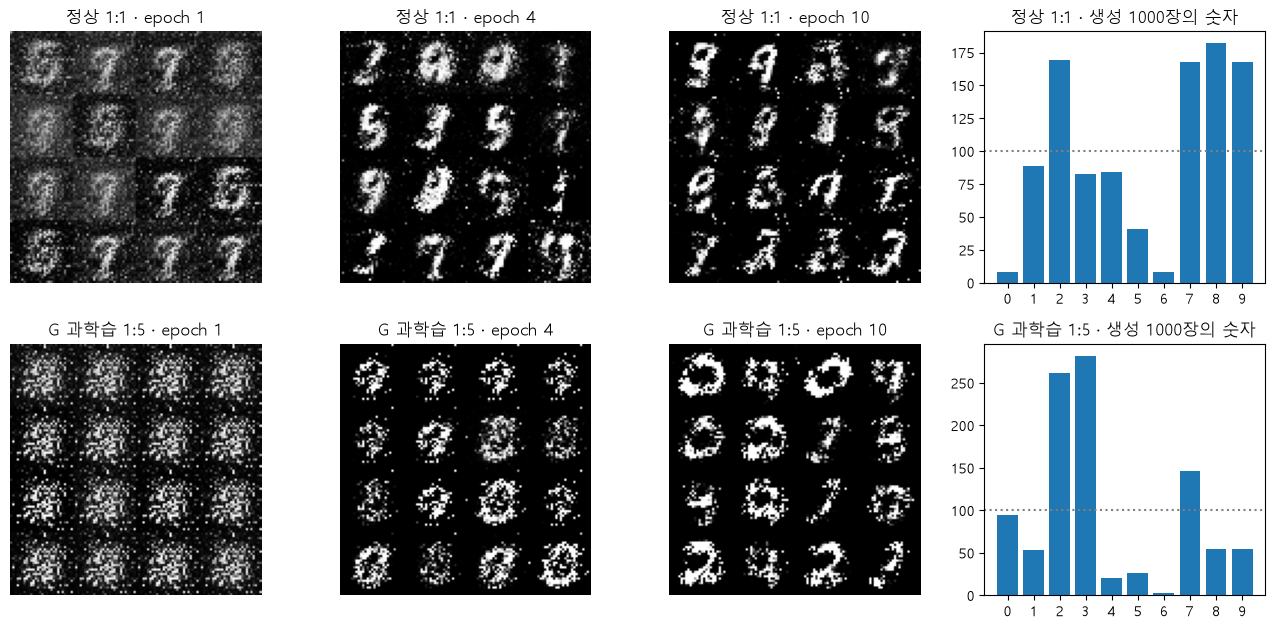

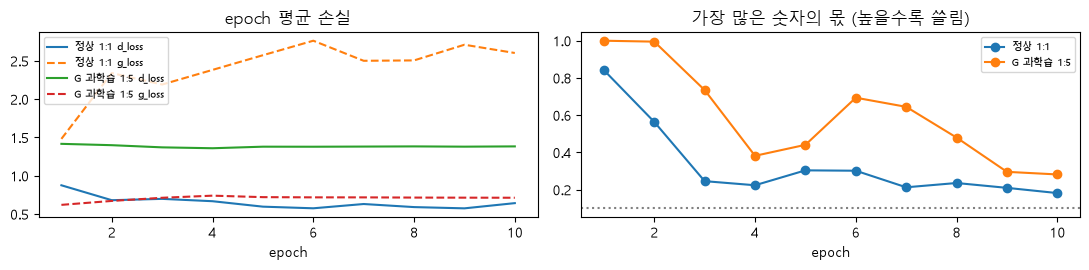

In [12]:
# [보강] 고정 z 16개의 학습 경과 · 손실 곡선 · 숫자 분포
fig, ax = plt.subplots(2, 4, figsize=(13, 6.4))
for r, (name, log) in enumerate(logs.items()):
    for c, (epoch, g) in enumerate(log["grid"].items()):
        tile = g.view(4, 4, 28, 28).permute(0, 2, 1, 3).reshape(112, 112)
        ax[r, c].imshow(tile, cmap="gray")
        ax[r, c].set_title(f"{name} · epoch {epoch}")
        ax[r, c].axis("off")
    ax[r, 3].bar(range(10), log["q"]["counts"])
    ax[r, 3].axhline(100, ls=":", c="gray")  # 고르면 숫자마다 100개
    ax[r, 3].set_xticks(range(10))
    ax[r, 3].set_title(f"{name} · 생성 1000장의 숫자")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
for name, log in logs.items():
    ep = range(1, EPOCHS + 1)
    ax[0].plot(ep, log["d_loss"], label=f"{name} d_loss")
    ax[0].plot(ep, log["g_loss"], "--", label=f"{name} g_loss")
    ax[1].plot(ep, log["top"], marker="o", label=name)
ax[0].set_title("epoch 평균 손실")
ax[1].axhline(0.1, ls=":", c="gray")  # 고르면 숫자마다 0.1
ax[1].set_title("가장 많은 숫자의 몫 (높을수록 쏠림)")
for a in ax:
    a.set_xlabel("epoch")
    a.legend(fontsize=7)
plt.tight_layout()
plt.show()

**예측 정답** · **1.0** — 첫 epoch에는 1000장이 전부 같은 숫자(완전 붕괴), 2 epoch 0.99, 이후 쏠리는 숫자가 바뀌며(모드 호핑) 0.28까지 내려옴

**결과 해설** · GPU(RTX 3060)에서 실행한 값, 같은 seed로 두 번 실행해 같은 값 확인 (학습 시간 초는 실행마다 다름)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">출력</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>평가용 분류기 테스트 정확도: 0.9731</code></td>
<td style="text-align: left;">평가 도구 자체가 97% 정확 → 숫자 세기에 쓸 만함</td>
</tr>
<tr>
<td style="text-align: left;"><code>진짜 1000장 기준 &#124; 숫자 10종 &#124; 최다 몫 0.121 &#124; 다양성 10.04 &#124; 선명도 0.913</code></td>
<td style="text-align: left;">진짜 데이터의 기준값</td>
</tr>
<tr>
<td style="text-align: left;"><code>숫자 8종 &#124; 최다 몫 0.182 &#124; 다양성 9.02 &#124; 선명도 0.867</code></td>
<td style="text-align: left;">정상 1:1 — 그럴듯하지만 2종이 3% 미만</td>
</tr>
<tr>
<td style="text-align: left;"><code>숫자별 개수 [8, 89, 169, 83, 84, 41, 8, 168, 182, 168]</code></td>
<td style="text-align: left;">정상 1:1 — 0 · 6이 각 8개뿐 = <strong>부분 붕괴</strong>(모드 누락)</td>
</tr>
<tr>
<td style="text-align: left;"><code>epoch별 최다 숫자 몫 [0.84, 0.56, 0.25, 0.22, 0.3, 0.3, 0.21, 0.24, 0.21, 0.18]</code></td>
<td style="text-align: left;">정상 1:1 — 초반 쏠림이 점점 풀림</td>
</tr>
<tr>
<td style="text-align: left;"><code>숫자 7종 &#124; 최다 몫 0.282 &#124; 다양성 9.57 &#124; 선명도 0.948</code></td>
<td style="text-align: left;">G 과학습 1:5 — 종류는 더 적은데 다양성 · 선명도는 오히려 높음</td>
</tr>
<tr>
<td style="text-align: left;"><code>숫자별 개수 [95, 54, 262, 282, 21, 26, 3, 147, 55, 55]</code></td>
<td style="text-align: left;">G 과학습 1:5 — 2 · 3에 쏠리고 6은 거의 없음</td>
</tr>
<tr>
<td style="text-align: left;"><code>epoch별 최다 숫자 몫 [1.0, 0.99, 0.73, 0.38, 0.44, 0.69, 0.65, 0.48, 0.3, 0.28]</code></td>
<td style="text-align: left;">G 과학습 1:5 — 완전 붕괴로 시작, 오르내림 = 모드 호핑</td>
</tr>
</tbody>
</table>

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">지표</th>
<th style="text-align: left;">진짜</th>
<th style="text-align: left;">정상 1:1</th>
<th style="text-align: left;">G 과학습 1:5</th>
<th style="text-align: left;">읽는 법</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">숫자 종류</td>
<td style="text-align: left;">10</td>
<td style="text-align: left;">8</td>
<td style="text-align: left;">7</td>
<td style="text-align: left;">둘 다 모드 누락, 1:5가 더 심함</td>
</tr>
<tr>
<td style="text-align: left;">최다 몫</td>
<td style="text-align: left;">0.121</td>
<td style="text-align: left;">0.182</td>
<td style="text-align: left;">0.282</td>
<td style="text-align: left;">1:5가 더 쏠림</td>
</tr>
<tr>
<td style="text-align: left;">다양성</td>
<td style="text-align: left;">10.04</td>
<td style="text-align: left;">9.02</td>
<td style="text-align: left;">9.57</td>
<td style="text-align: left;"><strong>픽셀 거리만으로는 붕괴를 놓침</strong> (1:5가 더 높음)</td>
</tr>
<tr>
<td style="text-align: left;">선명도</td>
<td style="text-align: left;">0.913</td>
<td style="text-align: left;">0.867</td>
<td style="text-align: left;">0.948</td>
<td style="text-align: left;">또렷함과 다양성은 별개</td>
</tr>
<tr>
<td style="text-align: left;">판별자 손실 끝값</td>
<td style="text-align: left;">기준 1.386</td>
<td style="text-align: left;">0.643</td>
<td style="text-align: left;">1.384</td>
<td style="text-align: left;">1:5는 판별자가 따라오지 못해 반반 상태</td>
</tr>
</tbody>
</table>

**그림 읽는 법** · 위 줄 = 정상, 아래 줄 = G 과학습. 같은 고정 z 16개로 epoch 1 · 4 · 10을 그린 격자 → G 과학습의 epoch 1은 16칸이 거의 같은 모양(완전 붕괴), 정상은 epoch 1부터 여러 모양. 막대그래프는 생성 1000장의 숫자 분포(점선 = 고르면 100개). 아래 그래프 왼쪽은 epoch 평균 손실, 오른쪽은 최다 숫자 몫(점선 0.1 = 고름)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">숫자 분포 (분류기)</td>
<td style="text-align: left;">어떤 종류가 빠졌는지 직접 보임, 평가용 분류기가 필요</td>
<td style="text-align: left;">모드 누락 진단 (FID의 Inception 특징과 같은 발상)</td>
</tr>
<tr>
<td style="text-align: left;">다양성 (평균 거리)</td>
<td style="text-align: left;">계산이 쉽지만 픽셀 차이라 종류 누락을 놓칠 수 있음</td>
<td style="text-align: left;">학습 중 빠른 경고 (계속 줄면 붕괴)</td>
</tr>
<tr>
<td style="text-align: left;">선명도</td>
<td style="text-align: left;">흐림 · 또렷함만 봄, 종류는 모름</td>
<td style="text-align: left;">품질 축 (Precision에 가까운 감각)</td>
</tr>
<tr>
<td style="text-align: left;">고정 z 격자</td>
<td style="text-align: left;">같은 z의 시점별 변화 → 호핑 · 붕괴가 눈에 보임</td>
<td style="text-align: left;">체크포인트마다 저장해 나란히 비교</td>
</tr>
<tr>
<td style="text-align: left;">FID · Precision · Recall</td>
<td style="text-align: left;">특징 공간에서 분포 비교 (위클리 11 실험 3)</td>
<td style="text-align: left;">논문 · 보고용 표준 지표</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 정상 1:1도 숫자 0 · 6을 거의 만들지 않음 → \"그럴듯한 이미지가 나온다\"만으로 정상이라 판단하지 말고, 종류 분포까지 확인

> ✅ **한 줄 정리** · 생성 품질은 선명도와 다양성 두 축으로 보며, 모드 붕괴는 손실이나 픽셀 거리보다 생성 결과의 종류 분포와 고정 z 격자에서 가장 잘 드러난다.

**딥러닝 코드에서는** · 프로젝트에서는 epoch마다 `fixed_z` 격자 이미지와 다양성 수치를 저장하고, 끝난 뒤 FID(`torchmetrics.image.fid` 등)로 비교. 대응은 2-3처럼 한 번에 하나씩 바꿔 효과를 확인

---
## 5. 백지 복습

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 5-1. 질문에 답하기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">🎯 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">생성자와 판별자는 각각 무엇을 입력받아 무엇을 내는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">판별자 갱신 때 detach를 하는 이유와, 생성자 손실로 -log D(G(z))를 쓰는 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">GAN 손실 곡선이 균형점 근처면 학습이 잘 된 것인가?</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">판별자가 너무 강할 때와 너무 약할 때 각각 무슨 일이 생겼나?</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">모드 붕괴는 무엇이고 어떤 수치로 알아보는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">Minibatch StdDev는 어떻게 모드 붕괴를 줄이는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">전방향 과정에서 t가 커지면 무엇이 남는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">Diffusion은 GAN · 오토인코더와 무엇이 다른가?</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">생성 품질을 볼 두 축과, 모드 붕괴를 가장 잘 보여 준 지표는?</td>
</tr>
</tbody>
</table>

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 5-2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. 판별자 로짓 `torch.tensor([[0.0]])`(확률 0.5)에 진짜 라벨 1을 준 `BCEWithLogitsLoss` 값을 소수 넷째 자리로 출력
2. `x = torch.tensor([[0., 0.], [3., 4.]])` 두 점의 평균 거리(`torch.pdist`)를 출력
3. `betas = torch.linspace(1e-4, 0.02, 1000)`에서 t = 999의 √ᾱ를 소수 넷째 자리로 출력
4. 생성 숫자 개수 `torch.tensor([0, 50, 950])`에서 가장 많은 숫자의 몫을 출력

In [13]:
# 5-2 직접 작성

### 5-3. 모범 답안 · 5-1 · 5-2를 다 쓴 뒤에 보기

#### 5-1 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">생성자 = z → 가짜 데이터, 판별자 = 데이터 → 진짜일 점수(로짓)</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">detach는 판별자 손실이 생성자를 바꾸지 않게, -log D(G(z))는 초반(들킬 때)에도 기울기가 커서</td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">아님. 1차원 실험은 손실이 균형 근처인데 가운데 봉우리가 3%뿐 → 샘플을 봐야 함</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">강함 = 봉우리 3/8만 (품질은 높음), 약함 = 품질 0 (생성자가 못 배움)</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">z가 달라도 출력이 몇 가지로 몰림, 배치 다양성(평균 거리)이 진짜보다 크게 작음 (0.1749 vs 2.5395)</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">배치 안 표준편차를 판별자 특징으로 붙여, 단조로운 배치를 가짜로 알아보게 함 (1/8 → 8/8)</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">원본 비중 √ᾱ가 0으로 줄고 표준 정규분포 노이즈만 남음</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">경쟁 없이 넣은 노이즈를 맞히는 MSE로 학습, 품질 · 다양성은 높지만 생성에 수십 ~ 1000단계</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">선명도 · 다양성. 붕괴는 숫자 분포(최다 몫 · 종류)와 고정 z 격자에서 가장 잘 보임 (픽셀 거리는 놓침)</td>
</tr>
</tbody>
</table>

#### 5-2 답

```python
# 1. 확률 0.5에 정답 1 → -log 0.5 = ln2
loss = nn.BCEWithLogitsLoss()(torch.tensor([[0.0]]), torch.tensor([[1.0]]))
print(round(loss.item(), 4))  # 0.6931

# 2. 두 점 (0, 0) · (3, 4)의 거리
print(torch.pdist(torch.tensor([[0., 0.], [3., 4.]])).tolist())  # [5.0]

# 3. 마지막 시점의 원본 비중
betas = torch.linspace(1e-4, 0.02, 1000)
print(round(torch.cumprod(1 - betas, 0)[999].sqrt().item(), 4))  # 0.0064

# 4. 가장 많은 숫자의 몫
counts = torch.tensor([0, 50, 950])
print(round((counts.max() / counts.sum()).item(), 2))  # 0.95
```

---
## 6. 면접 30초 답변

**Q1. GAN에서 생성자와 판별자의 역할은 무엇인가요?**
> 생성자는 정규분포에서 뽑은 잠재 벡터를 받아 가짜 데이터를 만들고, 판별자는 입력이 진짜일 확률을 내는 이진 분류기입니다. 판별자는 진짜를 1, 가짜를 0으로 맞히도록, 생성자는 판별자가 가짜를 진짜라고 하도록 번갈아 학습합니다. 생성자는 진짜 데이터를 직접 보지 않고 판별자를 거친 기울기로만 배우며, 학습 후 생성에는 생성자만 씁니다.

**Q2. GAN 학습이 잘 되는지는 손실로 알 수 있나요?**
> 두 손실은 서로 상대적이라 품질의 척도가 아닙니다. 제 1차원 실험에서 판별자 손실이 균형점 근처였는데도 봉우리 3개 중 가운데 하나를 거의 만들지 않았고, 판별자가 약한 설정은 손실이 정상과 거의 같은데 품질이 0이었습니다. 그래서 고정 z 샘플 그림, 다양성 수치, FID 같은 별도 지표를 함께 봅니다.

**Q3. 모드 붕괴는 무엇이고 어떻게 대응하나요?**
> 서로 다른 잠재 벡터를 넣어도 몇 가지 비슷한 출력만 나오는 현상입니다. 생성자 손실은 샘플이 진짜 같은지만 묻고 서로 다른지는 묻지 않기 때문에, 판별자를 가장 잘 속이는 몇 곳으로 몰립니다. 먼저 데이터 · z 샘플링 오류를 점검하고, 생성자 · 판별자 균형을 맞추고, 판별자에 Minibatch StdDev 같은 다양성 장치를 넣습니다. 2차원 실험에서 이 장치만으로 봉우리 1개가 8개로 돌아왔습니다.

**Q4. Diffusion 모델이 GAN보다 안정적인 이유는요?**
> Diffusion은 데이터에 정해진 일정으로 노이즈를 더해 두고, 신경망이 넣은 노이즈를 맞히는 MSE 회귀 하나를 학습합니다. 상대가 움직이는 미니맥스 게임이 없어 학습이 안정적이고 데이터 전체를 덮도록 학습돼 모드 붕괴가 드뭅니다. 대신 생성할 때 노이즈를 수십 ~ 1000단계에 걸쳐 빼야 해서 느리고, DDIM이나 잠재 공간 확산으로 단계 수나 단계당 계산을 줄입니다.

---
## 7. 전체 코드

0 ~ 4장 코드를 한 셀에 모음. **이 셀만 실행해도 전체가 동작**하며(모든 학습 포함, GPU에서 10분 안팎), 그림은 각 섹션에서 보고 여기서는 닫음(`plt.close`). 섹션 구분은 `# ===== [번호]` 주석.

In [14]:
# ===== [0-1]
# [보강] 라이브러리 · 재현성 · 장치 설정
import os
import random
import time
from pathlib import Path

if "KMP_DUPLICATE_LIB_OK" not in os.environ:  # Windows Anaconda 충돌 방지
    os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"  # numpy · torch OpenMP 중복
if "CUBLAS_WORKSPACE_CONFIG" not in os.environ:  # GPU 행렬 곱 결정적으로
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # torch 불러오기 전에

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
from matplotlib import font_manager
from torch import nn

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # CPU · GPU 난수 모두 고정
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True  # 합성곱 결정적
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)  # 나머지 연산도 결정적


set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":  # 계산은 GPU가 하므로 CPU 스레드는 1개로
    torch.set_num_threads(1)  # 작은 CPU 연산(증강 등)의 스레드 경쟁 방지
print("torch", torch.__version__, "| device:", device)


# 그림 한글 글꼴 (있을 때만)
fonts = {f.name for f in font_manager.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if name in fonts:
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False
bce = nn.BCEWithLogitsLoss()  # 판별자 출력 = 로짓 (sigmoid 전 점수)


def mlp(n_in, n_out, act, hidden=32):  # 은닉층 2개짜리 작은 신경망
    return nn.Sequential(nn.Linear(n_in, hidden), act,
                         nn.Linear(hidden, hidden), act,
                         nn.Linear(hidden, n_out))


# ===== [0-2]
# [보강] MNIST: 없으면 내려받음 (약 12MB, 처음 1번) · 3-1과 4장에서 사용
DATA = Path("data")  # 노트북 옆 data/ 폴더
mnist = torchvision.datasets.MNIST(DATA, train=True, download=True)
X_mnist = (mnist.data.float() / 255 * 2 - 1).view(-1, 784)  # -1 ~ 1, 펼침
Y_mnist = mnist.targets
print("MNIST:", tuple(mnist.data.shape), mnist.data.dtype,
      "→ X_mnist:", tuple(X_mnist.shape),
      "| 범위:", X_mnist.min().item(), "~", X_mnist.max().item())


# ===== [1-1]
# [보강] 진짜 데이터: -3 · 0 · 3 중심 봉우리 3개 (표준편차 0.3)
MODES_1D = torch.tensor([-3.0, 0.0, 3.0])


def real_1d(n, gen):
    k = torch.randint(0, 3, (n,), generator=gen)  # 봉우리 고르기
    return (MODES_1D[k] + 0.3 * torch.randn(n, generator=gen))[:, None]


# 생성자 G: 잠재 벡터 z(4개 숫자) → 가짜 값 1개
# 판별자 D: 값 1개 → 진짜일 점수(로짓) 1개
Z1 = 4
set_seed()
G1 = mlp(Z1, 1, nn.Tanh())
D1 = mlp(1, 1, nn.LeakyReLU(0.2))
gen = torch.Generator().manual_seed(SEED)
z = torch.randn(8, Z1, generator=gen)  # 정규분포에서 뽑은 잠재 벡터
real, fake = real_1d(8, gen), G1(z)
print("z:", tuple(z.shape), "→ G(z):", tuple(fake.shape),
      "| 진짜:", tuple(real.shape))
print("D(진짜):", tuple(D1(real).shape), "| D(가짜):", tuple(D1(fake).shape))


# 학습 전: 판별자는 아직 구분 못 함 → 확률 0.5 근처
with torch.no_grad():
    print("학습 전 진짜일 확률 · 진짜:",
          round(torch.sigmoid(D1(real)).mean().item(), 4),
          "| 가짜:", round(torch.sigmoid(D1(fake)).mean().item(), 4))
print("파라미터 · G:", sum(p.numel() for p in G1.parameters()),
      "| D:", sum(p.numel() for p in D1.parameters()))


# ===== [1-2]
# [보강] 학습 한 단계: ① 판별자 갱신 → ② 생성자 갱신
opt_g = torch.optim.Adam(G1.parameters(), lr=2e-3, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(D1.parameters(), lr=2e-3, betas=(0.5, 0.999))
ones, zeros = torch.ones(64, 1), torch.zeros(64, 1)
real = real_1d(64, gen)
fake = G1(torch.randn(64, Z1, generator=gen))


# ① 판별자: 진짜 → 1, 가짜 → 0 (가짜는 detach로 G와 끊음)
d_loss = bce(D1(real), ones) + bce(D1(fake.detach()), zeros)
opt_d.zero_grad()
d_loss.backward()
print("D 갱신 때 G 기울기 없음:", G1[0].weight.grad is None)  # detach 효과
opt_d.step()


# ② 생성자: D가 가짜를 1(진짜)이라고 하도록 → D를 거친 기울기로만 배움
g_loss = bce(D1(fake), ones)  # = 평균 -log D(G(z))
opt_g.zero_grad()
g_loss.backward()
opt_g.step()
print(f"d_loss {d_loss.item():.4f} | g_loss {g_loss.item():.4f}")
print(f"균형점 기준값 · d_loss 2·ln2 = {2 * np.log(2):.4f}"
      f" | g_loss ln2 = {np.log(2):.4f}")


# 생성자 손실 두 가지: 가짜가 쉽게 들킬 때(p 작음) 기울기 크기
for p in [0.01, 0.1, 0.5, 0.9]:  # p = D(G(z)) 진짜일 확률
    s = torch.logit(torch.tensor(p)).requires_grad_()
    torch.log(1 - torch.sigmoid(s)).backward()  # 원래 식 (줄이기)
    g_orig, s.grad = s.grad.abs().item(), None
    (-torch.log(torch.sigmoid(s))).backward()  # non-saturating
    print(f"D(G(z))={p:<4} | 원래 식 기울기 {g_orig:.2f}"
          f" | non-saturating 기울기 {s.grad.abs().item():.2f}")


# ===== [1-3]
# [보강] 1차원 GAN 학습 2000단계 · 손실과 D 출력 기록
def train_1d(steps=2000):
    set_seed()
    G, D = mlp(Z1, 1, nn.Tanh()), mlp(1, 1, nn.LeakyReLU(0.2))
    G, D = G.to(device), D.to(device)
    og = torch.optim.Adam(G.parameters(), lr=2e-3, betas=(0.5, 0.999))
    od = torch.optim.Adam(D.parameters(), lr=2e-3, betas=(0.5, 0.999))
    gen = torch.Generator().manual_seed(SEED)
    one = torch.ones(64, 1, device=device)
    hist = {"d_loss": [], "g_loss": [], "D(real)": [], "D(fake)": []}
    for step in range(steps):
        real = real_1d(64, gen).to(device)
        fake = G(torch.randn(64, Z1, generator=gen).to(device))
        out_r, out_f = D(real), D(fake.detach())
        d_loss = bce(out_r, one) + bce(out_f, 0 * one)
        od.zero_grad()
        d_loss.backward()
        od.step()
        g_loss = bce(D(fake), one)
        og.zero_grad()
        g_loss.backward()
        og.step()
        for k, v in zip(hist, [d_loss, g_loss, torch.sigmoid(out_r).mean(),
                               torch.sigmoid(out_f).mean()]):
            hist[k].append(v.item())
    return G, hist


G1, hist1 = train_1d()
for k, v in hist1.items():  # 처음 50단계 평균 → 마지막 200단계 평균
    print(f"{k:7}: {np.mean(v[:50]):.4f} → {np.mean(v[-200:]):.4f}")


# 생성 2000개가 각 봉우리(중심 ± 0.9)에 몇 %씩 갔나
with torch.no_grad():
    sample = G1(torch.randn(2000, Z1, generator=gen).to(device)).cpu()[:, 0]
share = [((sample - m).abs() < 0.9).float().mean().item() for m in MODES_1D]
print("봉우리별 비율:", [round(s, 3) for s in share])


# 손실 곡선 · 진짜와 생성 분포
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for k in ["d_loss", "g_loss"]:
    ax[0].plot(np.convolve(hist1[k], np.ones(50) / 50, "valid"), label=k)
ax[0].axhline(2 * np.log(2), ls=":", c="gray")
ax[0].axhline(np.log(2), ls=":", c="gray")
ax[0].set_title("손실 (50단계 이동 평균)")
ax[0].legend()
for k in ["D(real)", "D(fake)"]:
    ax[1].plot(np.convolve(hist1[k], np.ones(50) / 50, "valid"), label=k)
ax[1].axhline(0.5, ls=":", c="gray")
ax[1].set_title("판별자 출력 (확률)")
ax[1].legend()
ax[2].hist(real_1d(2000, gen)[:, 0], bins=80, alpha=0.5, label="진짜")
ax[2].hist(sample, bins=80, alpha=0.5, label="생성")
ax[2].set_title("분포 비교")
ax[2].legend()
ax[0].set_xlabel("단계")
ax[1].set_xlabel("단계")
plt.tight_layout()
plt.close()


# ===== [2-1]
# [보강] 2차원 진짜 데이터: 반지름 2 원 위 봉우리 8개 (표준편차 0.1)
ang = torch.arange(8) * (2 * np.pi / 8)
CENTERS = torch.stack([2 * torch.cos(ang), 2 * torch.sin(ang)], dim=1)


def real_2d(n, gen):
    k = torch.randint(0, 8, (n,), generator=gen)
    return CENTERS[k] + 0.1 * torch.randn(n, 2, generator=gen)


class MinibatchStdDev(nn.Module):  # 2-3에서 사용: 배치 다양성을 특징 1개로
    def forward(self, h):
        s = h.std(dim=0, unbiased=False).mean()  # 샘플 간 표준편차의 평균
        return torch.cat([h, s.expand(h.shape[0], 1)], dim=1)


def make_d(mbstd=False):
    act = nn.LeakyReLU(0.2)
    layers = [nn.Linear(2, 64), act, nn.Linear(64, 64), act]
    if mbstd:
        layers += [MinibatchStdDev(), nn.Linear(65, 1)]
    else:
        layers += [nn.Linear(64, 1)]
    return nn.Sequential(*layers)


def train_2d(d_steps=1, g_steps=1, lr_d=1e-3, lr_g=1e-3, mbstd=False,
             steps=3000):
    set_seed()
    G = mlp(2, 2, nn.ReLU(), hidden=64).to(device)
    D = make_d(mbstd).to(device)
    og = torch.optim.Adam(G.parameters(), lr=lr_g, betas=(0.5, 0.999))
    od = torch.optim.Adam(D.parameters(), lr=lr_d, betas=(0.5, 0.999))
    gen = torch.Generator().manual_seed(SEED)
    one = torch.ones(64, 1, device=device)
    hist = {"d_loss": [], "g_loss": []}
    for step in range(steps):
        for _ in range(d_steps):  # 판별자 d_steps번
            real = real_2d(64, gen).to(device)
            fake = G(torch.randn(64, 2, generator=gen).to(device)).detach()
            d_loss = bce(D(real), one) + bce(D(fake), 0 * one)
            od.zero_grad()
            d_loss.backward()
            od.step()
        for _ in range(g_steps):  # 생성자 g_steps번
            fake = G(torch.randn(64, 2, generator=gen).to(device))
            g_loss = bce(D(fake), one)
            og.zero_grad()
            g_loss.backward()
            og.step()
        hist["d_loss"].append(d_loss.item())
        hist["g_loss"].append(g_loss.item())
    return G, hist


@torch.no_grad()
def check_2d(G, n=2000):  # 품질 · 잡은 봉우리 · 배치 다양성
    gen = torch.Generator().manual_seed(0)
    x = G(torch.randn(n, 2, generator=gen).to(device)).cpu()
    dist, k = torch.cdist(x, CENTERS).min(dim=1)  # 가장 가까운 봉우리
    good = dist < 0.3  # 봉우리 중심 0.3 이내 = 그럴듯한 샘플
    modes = int((torch.bincount(k[good], minlength=8) >= 50).sum())
    spread = torch.pdist(x[:500]).mean().item()  # 샘플끼리 평균 거리
    return x, dict(quality=good.float().mean().item(), modes=modes,
                   spread=spread)


# 기준 · 판별자 강함(5번씩 · 큰 lr) · 판별자 약함(아주 작은 lr)
runs_21 = {"기준 1:1": dict(),
           "D 강함": dict(d_steps=5, lr_d=5e-3),
           "D 약함": dict(lr_d=1e-5)}
res_21 = {}
for name, cfg in runs_21.items():
    G, hist = train_2d(**cfg)
    x, m = check_2d(G)
    res_21[name] = (x, hist)
    print(f"{name:7} | d_loss {np.mean(hist['d_loss'][-300:]):.4f}"
          f" | g_loss {np.mean(hist['g_loss'][-300:]):.4f}"
          f" | 품질 {m['quality']:.3f} | 봉우리 {m['modes']}/8")


# ===== [2-2]
# [보강] 모드 붕괴를 일부러: 생성자를 판별자보다 5배 자주 갱신
G_c, hist_c = train_2d(g_steps=5)
x_c, m_c = check_2d(G_c)
x_n, m_n = check_2d(train_2d()[0])  # 기준(1:1) 다시 학습 → 같은 결과
for name, m in [("정상 1:1", m_n), ("붕괴 1:5", m_c)]:
    print(f"{name} | 품질 {m['quality']:.3f} | 봉우리 {m['modes']}/8"
          f" | 배치 다양성(평균 거리) {m['spread']:.4f}")


# 진단 1: 서로 다른 z 5개 → 출력이 얼마나 다른가
z5 = torch.randn(5, 2, generator=torch.Generator().manual_seed(1))
with torch.no_grad():
    out = G_c(z5.to(device)).cpu()
print("붕괴 G의 z 5개 출력:", [[round(v, 2) for v in r] for r in out.tolist()])


# 진단 2: 진짜 데이터 사이 평균 거리 (다양성의 기준)
real = real_2d(500, torch.Generator().manual_seed(0))
print("진짜 데이터 배치 다양성:", round(torch.pdist(real).mean().item(), 4))


# ===== [2-3]
# [보강] 대응: 판별자에 Minibatch StdDev → 배치가 단조로우면 가짜로 알아봄
G_m, hist_m = train_2d(g_steps=5, mbstd=True)  # 붕괴 설정 그대로 + 장치
x_m, m_m = check_2d(G_m)
print(f"붕괴 1:5 + MinibatchStdDev | 품질 {m_m['quality']:.3f}"
      f" | 봉우리 {m_m['modes']}/8 | 배치 다양성 {m_m['spread']:.4f}")


# 같은 배치 통계를 다양한 배치 · 단조로운 배치에서 비교
layer = MinibatchStdDev()
varied = real_2d(64, torch.Generator().manual_seed(0))
same = varied[:1].repeat(64, 1)  # 한 점만 64번
print("붙는 특징 · 다양한 배치:", round(layer(varied)[0, -1].item(), 4),
      "| 같은 점 배치:", round(layer(same)[0, -1].item(), 4))


# 기준 · D 강함 · D 약함 · 붕괴 · 대응 산점도
panels = [(res_21[k][0], k) for k in runs_21] + [(x_c, "붕괴 1:5"),
                                                 (x_m, "1:5 + MBStd")]
fig, ax = plt.subplots(1, 5, figsize=(14, 2.9))
for a, (x, title) in zip(ax, panels):
    a.scatter(x[:, 0], x[:, 1], s=2, alpha=0.4)
    a.scatter(CENTERS[:, 0], CENTERS[:, 1], c="red", marker="x")
    a.set_title(title)
    a.set_xlim(-3, 3)
    a.set_ylim(-3, 3)
    a.set_aspect("equal")
plt.tight_layout()
plt.close()


# ===== [3-1]
# [보강] 노이즈 일정 (DDPM): β를 0.0001 → 0.02로 1000단계
T = 1000
betas = torch.linspace(1e-4, 0.02, T)
alphas = 1 - betas
abar = torch.cumprod(alphas, dim=0)  # ᾱ_t = (1-β_1)(1-β_2)…(1-β_t)


def add_noise(x0, t, gen):  # x_t = √ᾱ_t · x0 + √(1-ᾱ_t) · ε (한 번에)
    eps = torch.randn(x0.shape, generator=gen)
    return abar[t].sqrt() * x0 + (1 - abar[t]).sqrt() * eps


show_t = [0, 50, 200, 500, 999]
for t in show_t:
    print(f"t={t:3} | √ᾱ(원본 비중) {abar[t].sqrt():.4f}"
          f" | √(1-ᾱ)(노이즈 비중) {(1 - abar[t]).sqrt():.4f}")


# MNIST 숫자 1장과 2차원 데이터에 단계별로 노이즈 더하기
gen = torch.Generator().manual_seed(SEED)
digit = X_mnist[0].view(28, 28)  # -1 ~ 1
pts = real_2d(500, gen)
fig, ax = plt.subplots(2, len(show_t), figsize=(12, 5))
for c, t in enumerate(show_t):
    ax[0, c].imshow(add_noise(digit, t, gen), cmap="gray", vmin=-1, vmax=1)
    xt = add_noise(pts, t, gen)
    ax[1, c].scatter(xt[:, 0], xt[:, 1], s=2)
    ax[1, c].set_xlim(-3.5, 3.5)
    ax[1, c].set_ylim(-3.5, 3.5)
    ax[0, c].set_title(f"t = {t}")
    ax[0, c].axis("off")
plt.tight_layout()
plt.close()


# 마지막 x_T는 거의 표준 정규분포
xT = add_noise(pts, T - 1, gen)
print("x_T 평균:", [round(v, 3) for v in xT.mean(0).tolist()],
      "| 표준편차:", [round(v, 3) for v in xT.std(0).tolist()])


# ===== [3-2]
# [보강] 정확한 노이즈 예측기 ε*(x_t, t): 데이터가 봉우리 8개라 식으로 계산
#        (실제 Diffusion은 이 자리에 신경망을 MSE로 학습)
def eps_star(x, t):
    a = abar[t]
    var = a * 0.1 ** 2 + (1 - a)  # x_t의 봉우리별 분산
    mu = a.sqrt() * CENTERS  # x_t의 봉우리 중심
    d2 = ((x[:, None, :] - mu[None]) ** 2).sum(-1)  # (N, 8) 거리²
    w = torch.softmax(-d2 / (2 * var), dim=1)  # 어느 봉우리에서 왔을 확률
    score = (w[:, :, None] * (mu[None] - x[:, None, :])).sum(1) / var
    return -(1 - a).sqrt() * score  # score → 노이즈 예측


# 역방향: 순수 노이즈에서 출발해 1000단계 동안 노이즈를 조금씩 빼기
gen = torch.Generator().manual_seed(SEED)
x = torch.randn(500, 2, generator=gen)  # x_T ~ N(0, I)
snap = {}
for t in reversed(range(T)):
    if t in (999, 500, 200, 50, 0):
        snap[t] = x.clone()
    eps = eps_star(x, t)
    mean = (x - betas[t] / (1 - abar[t]).sqrt() * eps) / alphas[t].sqrt()
    noise = torch.randn(x.shape, generator=gen) if t > 0 else 0
    x = mean + betas[t].sqrt() * noise
dist, k = torch.cdist(x, CENTERS).min(dim=1)
good = dist < 0.3
print("생성 500개 · 품질:", round(good.float().mean().item(), 3),
      "| 봉우리:", int((torch.bincount(k[good], minlength=8) >= 20).sum()),
      "/ 8 | 신경망 호출 수:", T)
print("봉우리별 개수:", torch.bincount(k[good], minlength=8).tolist())


fig, ax = plt.subplots(1, len(snap) + 1, figsize=(14, 2.6))
for a, (t, s) in zip(ax, list(snap.items()) + [("생성 끝", x)]):
    a.scatter(s[:, 0], s[:, 1], s=2)
    a.scatter(CENTERS[:, 0], CENTERS[:, 1], c="red", marker="x", s=12)
    a.set_title(f"t = {t}" if t != "생성 끝" else t)
    a.set_xlim(-3.5, 3.5)
    a.set_ylim(-3.5, 3.5)
    a.set_aspect("equal")
plt.tight_layout()
plt.close()


# ===== [4-1]
# [보강] 평가용 숫자 분류기: 생성 이미지가 어떤 숫자인지 세는 도구 (FID의 Inception 역할)
set_seed()
clf = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(32 * 7 * 7, 10)).to(device)
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
Xc = ((X_mnist + 1) / 2).view(-1, 1, 28, 28).to(device)  # 0 ~ 1 이미지
Yc = Y_mnist.to(device)
gen = torch.Generator().manual_seed(SEED)
for epoch in range(2):
    perm = torch.randperm(len(Xc), generator=gen).to(device)
    for i in range(0, len(Xc), 256):
        b = perm[i:i + 256]
        loss = F.cross_entropy(clf(Xc[b]), Yc[b])
        opt.zero_grad()
        loss.backward()
        opt.step()
test = torchvision.datasets.MNIST(DATA, train=False, download=True)
with torch.no_grad():
    x_te = (test.data.float() / 255)[:, None].to(device)
    acc = (clf(x_te).argmax(1).cpu() == test.targets).float().mean().item()
print(f"평가용 분류기 테스트 정확도: {acc:.4f}")


@torch.no_grad()
def quality(img):  # img: (N, 784), 0 ~ 1
    counts = torch.bincount(clf(img.view(-1, 1, 28, 28)).argmax(1).cpu(),
                            minlength=10)
    return dict(counts=counts.tolist(),
                kinds=int((counts >= 0.03 * len(img)).sum()),  # 3% 넘는 숫자
                top=counts.max().item() / len(img),  # 가장 많은 숫자 몫
                spread=torch.pdist(img[:300]).mean().item(),  # 다양성
                sharp=((img < 0.1) | (img > 0.9)).float().mean().item())  # 선명도


real_q = quality(((X_mnist[:1000] + 1) / 2).to(device))
print(f"진짜 1000장 기준 | 숫자 {real_q['kinds']}종 | 최다 몫 {real_q['top']:.3f}"
      f" | 다양성 {real_q['spread']:.2f} | 선명도 {real_q['sharp']:.3f}")


# [보강] MNIST 작은 GAN (MLP): 판별자 1번 · 생성자 g_steps번씩 10 epoch
ZD, EPOCHS = 64, 10


def train_mnist(g_steps=1):
    set_seed()
    G = nn.Sequential(nn.Linear(ZD, 256), nn.LeakyReLU(0.2),
                      nn.Linear(256, 512), nn.LeakyReLU(0.2),
                      nn.Linear(512, 784), nn.Tanh()).to(device)  # -1 ~ 1
    D = nn.Sequential(nn.Linear(784, 512), nn.LeakyReLU(0.2),
                      nn.Linear(512, 256), nn.LeakyReLU(0.2),
                      nn.Linear(256, 1)).to(device)
    og = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
    od = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
    gen = torch.Generator().manual_seed(SEED)
    fixed_z = torch.randn(16, ZD, generator=gen).to(device)  # 경과 비교용
    X, B = X_mnist.to(device), 128
    one = torch.ones(B, 1, device=device)
    log = {"d_loss": [], "g_loss": [], "top": [], "grid": {}}
    for epoch in range(1, EPOCHS + 1):
        perm = torch.randperm(len(X), generator=gen).to(device)
        d_sum = g_sum = 0.0
        for i in range(0, len(X) - B + 1, B):
            real = X[perm[i:i + B]]
            fake = G(torch.randn(B, ZD, generator=gen).to(device))
            d_loss = bce(D(real), one) + bce(D(fake.detach()), 0 * one)
            od.zero_grad()
            d_loss.backward()
            od.step()
            for _ in range(g_steps):  # 생성자 g_steps번
                fake = G(torch.randn(B, ZD, generator=gen).to(device))
                g_loss = bce(D(fake), one)
                og.zero_grad()
                g_loss.backward()
                og.step()
            d_sum, g_sum = d_sum + d_loss.item(), g_sum + g_loss.item()
        n = len(X) // B
        log["d_loss"].append(d_sum / n)
        log["g_loss"].append(g_sum / n)
        with torch.no_grad():  # epoch마다 생성 1000장 점검
            z = torch.randn(1000, ZD, generator=gen).to(device)
            log["q"] = quality((G(z) + 1) / 2)
            log["top"].append(log["q"]["top"])  # 가장 많은 숫자의 몫
            if epoch in (1, 4, EPOCHS):
                log["grid"][epoch] = ((G(fixed_z) + 1) / 2).cpu()
    return log


logs = {}
for name, g_steps in [("정상 1:1", 1), ("G 과학습 1:5", 5)]:
    start = time.time()
    logs[name] = log = train_mnist(g_steps)
    q = log["q"]
    d, g = log["d_loss"], log["g_loss"]
    print(f"{name:10} | d_loss {d[0]:.3f} → {d[-1]:.3f}"
          f" | g_loss {g[0]:.3f} → {g[-1]:.3f}"
          f" | {time.time() - start:.0f}초")
    print(f"{'':10} | 숫자 {q['kinds']}종 | 최다 몫 {q['top']:.3f}"
          f" | 다양성 {q['spread']:.2f} | 선명도 {q['sharp']:.3f}")
    print(f"{'':10} | 숫자별 개수 {q['counts']}")
    tops = [round(t, 2) for t in log["top"]]
    print(f"{'':10} | epoch별 최다 숫자 몫 {tops}")


# ===== [4-2]
# [보강] 고정 z 16개의 학습 경과 · 손실 곡선 · 숫자 분포
fig, ax = plt.subplots(2, 4, figsize=(13, 6.4))
for r, (name, log) in enumerate(logs.items()):
    for c, (epoch, g) in enumerate(log["grid"].items()):
        tile = g.view(4, 4, 28, 28).permute(0, 2, 1, 3).reshape(112, 112)
        ax[r, c].imshow(tile, cmap="gray")
        ax[r, c].set_title(f"{name} · epoch {epoch}")
        ax[r, c].axis("off")
    ax[r, 3].bar(range(10), log["q"]["counts"])
    ax[r, 3].axhline(100, ls=":", c="gray")  # 고르면 숫자마다 100개
    ax[r, 3].set_xticks(range(10))
    ax[r, 3].set_title(f"{name} · 생성 1000장의 숫자")
plt.tight_layout()
plt.close()

fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
for name, log in logs.items():
    ep = range(1, EPOCHS + 1)
    ax[0].plot(ep, log["d_loss"], label=f"{name} d_loss")
    ax[0].plot(ep, log["g_loss"], "--", label=f"{name} g_loss")
    ax[1].plot(ep, log["top"], marker="o", label=name)
ax[0].set_title("epoch 평균 손실")
ax[1].axhline(0.1, ls=":", c="gray")  # 고르면 숫자마다 0.1
ax[1].set_title("가장 많은 숫자의 몫 (높을수록 쏠림)")
for a in ax:
    a.set_xlabel("epoch")
    a.legend(fontsize=7)
plt.tight_layout()
plt.close()

torch 2.11.0+cu128 | device: cuda


MNIST: (60000, 28, 28) torch.uint8 → X_mnist: (60000, 784) | 범위: -1.0 ~ 1.0
z: (8, 4) → G(z): (8, 1) | 진짜: (8, 1)
D(진짜): (8, 1) | D(가짜): (8, 1)
학습 전 진짜일 확률 · 진짜: 0.4101 | 가짜: 0.4471
파라미터 · G: 1249 | D: 1153
D 갱신 때 G 기울기 없음: True
d_loss 1.4708 | g_loss 0.7866
균형점 기준값 · d_loss 2·ln2 = 1.3863 | g_loss ln2 = 0.6931
D(G(z))=0.01 | 원래 식 기울기 0.01 | non-saturating 기울기 0.99
D(G(z))=0.1  | 원래 식 기울기 0.10 | non-saturating 기울기 0.90
D(G(z))=0.5  | 원래 식 기울기 0.50 | non-saturating 기울기 0.50
D(G(z))=0.9  | 원래 식 기울기 0.90 | non-saturating 기울기 0.10


d_loss : 1.3232 → 1.2038
g_loss : 0.7851 → 0.9013
D(real): 0.5218 → 0.5785
D(fake): 0.4666 → 0.4215
봉우리별 비율: [0.431, 0.03, 0.432]


기준 1:1  | d_loss 1.3664 | g_loss 0.7370 | 품질 0.863 | 봉우리 8/8


D 강함    | d_loss 0.7161 | g_loss 1.5883 | 품질 0.900 | 봉우리 3/8


...

x_T 평균: [-0.058, -0.024] | 표준편차: [0.914, 0.969]


생성 500개 · 품질: 0.984 | 봉우리: 8 / 8 | 신경망 호출 수: 1000
봉우리별 개수: [62, 73, 53, 59, 69, 62, 62, 52]


평가용 분류기 테스트 정확도: 0.9731
진짜 1000장 기준 | 숫자 10종 | 최다 몫 0.121 | 다양성 10.04 | 선명도 0.913


정상 1:1     | d_loss 0.876 → 0.643 | g_loss 1.482 → 2.603 | 37초
           | 숫자 8종 | 최다 몫 0.182 | 다양성 9.02 | 선명도 0.867
           | 숫자별 개수 [8, 89, 169, 83, 84, 41, 8, 168, 182, 168]
           | epoch별 최다 숫자 몫 [0.84, 0.56, 0.25, 0.22, 0.3, 0.3, 0.21, 0.24, 0.21, 0.18]


G 과학습 1:5  | d_loss 1.417 → 1.384 | g_loss 0.620 → 0.713 | 104초
           | 숫자 7종 | 최다 몫 0.282 | 다양성 9.57 | 선명도 0.948
           | 숫자별 개수 [95, 54, 262, 282, 21, 26, 3, 147, 55, 55]
           | epoch별 최다 숫자 몫 [1.0, 0.99, 0.73, 0.38, 0.44, 0.69, 0.65, 0.48, 0.3, 0.28]


---
## 8. 전체 최종 요약표

### 등급별 핵심

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">등급</th>
<th style="text-align: left;">주제</th>
<th style="text-align: left;">반드시 기억할 것</th>
<th style="text-align: left;">코드에서</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">역할</td>
<td style="text-align: left;">생성자 z → 가짜, 판별자 데이터 → 진짜 점수</td>
<td style="text-align: left;"><code>G(torch.randn(n, z_dim))</code> · <code>D(x)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">학습 한 단계</td>
<td style="text-align: left;">판별자(가짜 detach) → 생성자 번갈아</td>
<td style="text-align: left;"><code>bce(D(fake.detach()), 0)</code> · <code>bce(D(fake), 1)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">생성자 손실</td>
<td style="text-align: left;">-log D(G(z)) (non-saturating)</td>
<td style="text-align: left;"><code>bce(D(fake), ones)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">손실 읽기</td>
<td style="text-align: left;">균형점 1.386 · 0.693 근처면 정상, 품질은 샘플로</td>
<td style="text-align: left;"><code>d_loss</code> · <code>g_loss</code> · <code>D(real)</code> · <code>D(fake)</code> 기록</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">균형</td>
<td style="text-align: left;">판별자 너무 강함 · 약함 모두 실패</td>
<td style="text-align: left;">D:G 갱신 비 · lr</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">모드 붕괴</td>
<td style="text-align: left;">z가 달라도 같은 출력, 분포 · 격자로 진단</td>
<td style="text-align: left;"><code>torch.pdist</code> · 분류기 분포 · <code>fixed_z</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">Diffusion 전방향</td>
<td style="text-align: left;">x_t = √ᾱ·x0 + √(1-ᾱ)·ε, 끝은 순수 노이즈</td>
<td style="text-align: left;"><code>add_noise(x0, t)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">대응</td>
<td style="text-align: left;">Minibatch StdDev · 정규화 · TTUR, 하나씩</td>
<td style="text-align: left;"><code>MinibatchStdDev()</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">Diffusion 역방향</td>
<td style="text-align: left;">노이즈 예측을 조금씩 빼기, 느리지만 고르게</td>
<td style="text-align: left;">DDPM 샘플러 1000단계</td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">지표</td>
<td style="text-align: left;">선명도 · 다양성 두 축, FID · Precision · Recall</td>
<td style="text-align: left;">분류기 숫자 분포</td>
</tr>
</tbody>
</table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">✅ 할 것</th>
<th style="text-align: left;">⚠️ 하지 말 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">판별자 갱신은 <code>fake.detach()</code></td>
<td style="text-align: left;">생성자 단계에서 판별자도 <code>step()</code></td>
</tr>
<tr>
<td style="text-align: left;">판별자는 로짓 + <code>BCEWithLogitsLoss</code></td>
<td style="text-align: left;">sigmoid 두 번</td>
</tr>
<tr>
<td style="text-align: left;">고정 z 격자를 epoch마다 저장</td>
<td style="text-align: left;">손실만 보고 성공 · 실패 판단</td>
</tr>
<tr>
<td style="text-align: left;">z는 배치마다 새로 뽑기</td>
<td style="text-align: left;">z를 루프 밖에서 한 번만</td>
</tr>
<tr>
<td style="text-align: left;">대응 기법은 하나씩 바꿔 비교</td>
<td style="text-align: left;">여러 기법을 한꺼번에 넣기</td>
</tr>
<tr>
<td style="text-align: left;">종류 분포까지 확인</td>
<td style="text-align: left;">\"그럴듯해 보인다\"로 끝내기</td>
</tr>
</tbody>
</table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">짝</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">결론</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">생성자 vs 판별자</td>
<td style="text-align: left;">z → 가짜 vs 데이터 → 진짜 점수</td>
<td style="text-align: left;">학습 후 쓰는 것은 생성자</td>
</tr>
<tr>
<td style="text-align: left;">생성자 loss vs 판별자 loss</td>
<td style="text-align: left;">-log D(G(z)) vs 진짜 1 · 가짜 0 BCE</td>
<td style="text-align: left;">균형점 ln2 · 2·ln2, 값 자체는 품질이 아님</td>
</tr>
<tr>
<td style="text-align: left;">원래 식 vs non-saturating</td>
<td style="text-align: left;">log(1 - D) 줄이기 vs -log D 줄이기</td>
<td style="text-align: left;">초반 기울기가 살아 있는 non-saturating</td>
</tr>
<tr>
<td style="text-align: left;"><code>fake</code> vs <code>fake.detach()</code></td>
<td style="text-align: left;">G까지 기울기 vs D에서 끊음</td>
<td style="text-align: left;">D 갱신은 detach, G 갱신은 그대로</td>
</tr>
<tr>
<td style="text-align: left;">판별자 강함 vs 약함</td>
<td style="text-align: left;">D 출력 0에 붙음 vs 0.5에서 안 움직임</td>
<td style="text-align: left;">둘 다 G가 못 배움 → 균형</td>
</tr>
<tr>
<td style="text-align: left;">모드 붕괴 vs 정상</td>
<td style="text-align: left;">z가 달라도 같은 출력 vs 다른 출력</td>
<td style="text-align: left;">배치 다양성 · 종류 분포로 진단</td>
</tr>
<tr>
<td style="text-align: left;">완전 붕괴 vs 부분 붕괴 vs 호핑</td>
<td style="text-align: left;">한 점 vs 일부 누락 vs 시점마다 이동</td>
<td style="text-align: left;">그림 · 분류기 분포 · 고정 z 격자</td>
</tr>
<tr>
<td style="text-align: left;">다양성 vs 선명도</td>
<td style="text-align: left;">샘플끼리 얼마나 다른가 vs 픽셀이 또렷한가</td>
<td style="text-align: left;">둘 다 봐야 함 (Recall · Precision 개념)</td>
</tr>
<tr>
<td style="text-align: left;">오토인코더 vs GAN vs Diffusion</td>
<td style="text-align: left;">재구성 vs 게임 vs 노이즈 예측</td>
<td style="text-align: left;">빠름 · 선명 · 품질 순서로 선택</td>
</tr>
<tr>
<td style="text-align: left;">전방향 vs 역방향</td>
<td style="text-align: left;">식으로 노이즈 더하기 vs 학습한 예측으로 빼기</td>
<td style="text-align: left;">학습은 전방향으로 만든 데이터로</td>
</tr>
</tbody>
</table>